**Phân loại âm thanh đô thị bằng học sâu**

**Mục lục**

- [1. Mục tiêu và tiêu chí đánh giá](#muc-tieu)
  - [1.1. Cấu hình môi trường](#c1-1)
- [2. Cấu hình và nạp dữ liệu](#c2)
  - [2.1. Đường dẫn, lớp và tham số âm thanh](#c2-1)
  - [2.2. Tìm metadata và file âm thanh](#c2-2)
  - [2.3. Kiểm tra file lỗi và bản sao](#c2-3)
- [3. Khảo sát dữ liệu và tiền xử lý](#khao-sat)
  - [3.1. Phân bố số mẫu](#c3-1)
  - [3.2. Chuẩn hóa waveform và Log-Mel](#c3-2)
  - [3.3. Waveform và spectrogram mẫu](#c3-3)
- [4. Chia tập và kiểm soát rò rỉ](#chia-tap)
  - [4.1. Chia theo nhóm fsID](#c4-1)
  - [4.2. Per-Bin Z-score](#c4-2)
  - [4.3. Dataset và DataLoader](#c4-3)
- [5. Các mô hình phân loại](#mo-hinh)
  - [5.1. Custom 2D-CNN tự xây dựng](#c5-1)
  - [5.2. Custom ResAttention-CNN](#c5-2)
  - [5.3. Các mô hình pretrained](#c5-3)
- [6. Huấn luyện, transfer learning và fine-tuning](#huan-luyen)
  - [6.1. Hàm đánh giá và optimizer](#c6-1)
  - [6.2. Huấn luyện và chọn theo Validation](#c6-2)
  - [6.3. Learning curves so sánh](#c6-3)
  - [6.4. Đường cong riêng từng mô hình](#c6-4)
  - [6.5. Khoảng cách Train–Validation](#c6-5)
- [7. Đánh giá phân loại](#danh-gia)
  - [7.1. Accuracy, Precision, Recall, F1](#c7-1)
  - [7.2. So sánh và ma trận nhầm lẫn](#c7-2)
  - [7.3. Phân tích lỗi nhầm lẫn](#c7-3)
  - [7.4. ROC-AUC One-vs-Rest](#c7-4)
- [8. Thí nghiệm đối chứng](#ablation)
  - [8.1. Giả thuyết về lớp Còi hú](#c8-1)
  - [8.2. Đặc trưng và chuẩn hóa](#c8-2)
    - [8.2.1. Các chế độ đặc trưng](#c8-2-1)
  - [8.3. Regularization và learning rate](#c8-3)
    - [8.3.1. Cấu hình đối chiếu](#c8-3-1)
  - [8.4. Cửa sổ trượt và gộp xác suất](#c8-4)
    - [8.4.1. Điều kiện đánh giá](#c8-4-1)
- [9. PCA và hiệu năng triển khai](#pca-hieu-nang)
  - [9.1. PCA trên embedding](#c9-1)
    - [9.1.1. Cách đọc biểu đồ PCA](#c9-1-1)
  - [9.2. Dung lượng và tốc độ suy luận](#c9-2)
    - [9.2.1. Cách diễn giải phép đo](#c9-2-1)
- [10. Demo và kết luận](#demo-ket-luan)
  - [10.1. Demo một tệp âm thanh](#c10-1)
  - [10.2. Báo cáo kết quả](#c10-2)


<a id="muc-tieu"></a>
# 1. Mục tiêu và tiêu chí đánh giá

Bài toán phân loại âm thanh đô thị 7 lớp sử dụng bộ dữ liệu UrbanSound8K.Nghiên cứu thực hiện xây dựng và đối chiếu 3 mô hình: **CNN 4 khối tự xây dựng**, **CNN residual tự xây dựng (ResCNN)** và **Audio Spectrogram Transformer (AST pretrained trên AudioSet)** kết hợp cùng phương pháp **Ensemble xác suất**.



<a id="c1-1"></a>
## 1.1. Cấu hình môi trường


In [1]:
import os, sys, subprocess, importlib.util
os.environ['USE_TF'] = '0'
os.environ['USE_FLAX'] = '0'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['HF_HUB_DISABLE_XET'] = '1'

if importlib.util.find_spec('torch') is None:
    raise RuntimeError('Môi trường chưa có PyTorch. Hãy bật GPU trên Kaggle.')

requirements = [
    'transformers>=4.40.0', 'librosa>=0.10.2,<0.12', 'soundfile>=0.12',
    'safetensors>=0.4.3', 'scikit-learn', 'tqdm', 'seaborn', 'matplotlib'
]
subprocess.run([sys.executable, '-m', 'pip', 'install', '--quiet', *requirements], check=False)
print('Đã kiểm tra và cài đặt xong các thư viện phụ trợ; giữ nguyên PyTorch/CUDA của Kaggle.')


Đã kiểm tra và cài đặt xong các thư viện phụ trợ; giữ nguyên PyTorch/CUDA của Kaggle.


In [2]:
import re, gc, json, time, math, random, shutil, hashlib, warnings
from pathlib import Path
from collections import OrderedDict
from contextlib import nullcontext

import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import librosa.display
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.decomposition import PCA
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    precision_recall_fscore_support, classification_report,
    confusion_matrix, roc_curve, auc, average_precision_score
)
from transformers import AutoConfig, AutoFeatureExtractor, ASTForAudioClassification
from IPython.display import display, Markdown, Audio, FileLink

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.labelsize'] = 10

def seed_all(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

SEED = 42
seed_all(SEED)
DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()
    print(f'Đã kích hoạt GPU thành công: {torch.cuda.get_device_name(0)}')
else:
    print('Cảnh báo: Đang chạy trên CPU. Khuyến nghị bật GPU để huấn luyện AST nhanh hơn.')
print('PyTorch:', torch.__version__, '| Thiết bị:', DEVICE)


Đã kích hoạt GPU thành công: Tesla T4
PyTorch: 2.11.0+cu128 | Thiết bị: cuda:0


<a id="c2"></a>
# 2. Cấu hình và nạp dữ liệu

<a id="c2-1"></a>
## 2.1. Đường dẫn, lớp và tham số âm thanh


In [3]:
CLASSES = ['car_horn', 'children_playing', 'dog_bark', 'engine_idling', 'gun_shot', 'siren', 'drilling']
VI = ['Còi xe', 'Trẻ em vui chơi', 'Chó sủa', 'Động cơ chạy không tải', 'Tiếng súng', 'Còi báo động', 'Tiếng khoan']
CLASS_DISPLAY = dict(zip(CLASSES, VI))
CLASS2ID = {c: i for i, c in enumerate(CLASSES)}
ID2CLASS = {i: c for i, c in enumerate(CLASSES)}

MODEL_NAMES = OrderedDict([
    ('cnn4', 'CNN 4 khối'),
    ('rescnn', 'ResCNN tự xây dựng'),
    ('ast', 'AST Pretrained'),
    ('ensemble', 'Ensemble xác suất')
])

CFG = {
    'experiment_name': 'urban_sound_7class',
    'input_root': '/kaggle/input',
    'data_csv': '',
    'demo_path': '/kaggle/input/datasets/f8kinwd/drilling',
    'mode': 'full',
    'seed': 42,
    'models': ['cnn4', 'rescnn', 'ast'],
    'test_fold': 10,
    'val_fold': 1,
    'sr': 16000,
    'seconds': 4.0,
    'n_mels_cnn': 64,
    'n_fft': 1024,
    'hop_length': 256,
    'cnn_epochs': 45,
    'ast_epochs': 12,
    'cnn_batch': 16,
    'ast_batch': 2,
    'ast_accum': 8,
    'cnn_lr': 8e-4,
    'ast_lr': 1e-5,
    'weight_decay': 5e-4,
    'patience': 10,
    'amp': True,
    'gradient_checkpointing': True,
    'ast_id': 'MIT/ast-finetuned-audioset-10-10-0.4593',
    'ast_local_path': '',
    'demo_threshold': 0.60,
    'silence_rms': 1e-4
}

ROOT = Path('/kaggle/working') / CFG['experiment_name']
CHECKPOINT_DIR = ROOT / 'outputs/checkpoints'
DATA_OUT_DIR = ROOT / 'outputs/data'
FIGURES_DIR = ROOT / 'outputs/figures'
INDIVIDUAL_FIG_DIR = FIGURES_DIR / 'individual_models'
METRICS_DIR = ROOT / 'outputs/metrics'
PRED_DIR = ROOT / 'outputs/predictions'
LOGS_DIR = ROOT / 'outputs/logs'

for d in [CHECKPOINT_DIR, DATA_OUT_DIR, FIGURES_DIR, INDIVIDUAL_FIG_DIR, METRICS_DIR, PRED_DIR, LOGS_DIR, ROOT / 'cache']:
    d.mkdir(parents=True, exist_ok=True)

def dump_json(obj, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(obj, ensure_ascii=False, indent=2, default=str), encoding='utf-8')

def save_fig(fig, filename, subfolder=None):
    target_dir = INDIVIDUAL_FIG_DIR if subfolder == 'individual' else FIGURES_DIR
    stem = Path(filename).stem
    fig.savefig(target_dir / f"{stem}.png", dpi=300, bbox_inches='tight')
    fig.savefig(target_dir / f"{stem}.svg", bbox_inches='tight')

dump_json(CFG, ROOT / 'configs_experiment.json')
display(pd.DataFrame({'Tham số cấu hình': list(CFG.keys()), 'Giá trị': [str(v) for v in CFG.values()]}))
print('Thư mục lưu kết quả:', ROOT)
print('Đường dẫn dữ liệu kiểm thử (Demo/Test):', CFG['demo_path'])


,Tham số cấu hình,Giá trị
0,experiment_name,urban_sound_7class
1,input_root,/kaggle/input
2,data_csv,
3,demo_path,/kaggle/input/datasets/f8kinwd/drilling
4,mode,full
5,seed,42
6,models,"['cnn4', 'rescnn', 'ast']"
7,test_fold,10
8,val_fold,1
9,sr,16000


Thư mục lưu kết quả: /kaggle/working/urban_sound_7class
Đường dẫn dữ liệu kiểm thử (Demo/Test): /kaggle/input/datasets/f8kinwd/drilling


<a id="c2-2"></a>
## 2.2. Tìm metadata và file âm thanh


In [4]:
def sha_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

def locate_urbansound_metadata(input_root, explicit_csv=''):
    required = {'slice_file_name', 'fold', 'class'}
    candidates = [Path(explicit_csv)] if explicit_csv else list(Path(input_root).rglob('UrbanSound8K.csv'))
    valid = []
    for p in candidates:
        try:
            d = pd.read_csv(p)
            if required.issubset(d.columns):
                valid.append((p, d))
        except Exception:
            pass
    if not valid:
        raise FileNotFoundError('Không tìm thấy UrbanSound8K.csv trong /kaggle/input. Hãy gắn bộ dữ liệu UrbanSound8K vào Input.')
    return valid[0]

csv_path, raw_meta_df = locate_urbansound_metadata(CFG['input_root'], CFG['data_csv'])
print(f'Tìm thấy file metadata CSV: {csv_path}')

df = raw_meta_df[raw_meta_df['class'].isin(CLASSES)].copy()
df['label'] = df['class'].map(CLASS2ID).astype(int)
df['fold'] = pd.to_numeric(df['fold'], errors='raise').astype(int)

def canon_source(v):
    s = str(v)
    return str(int(float(s))) if s.replace('.', '', 1).isdigit() else s

df['source_id'] = df['fsID'].map(canon_source) if 'fsID' in df.columns else df['slice_file_name'].str.split('-').str[0]
df = df.drop_duplicates('slice_file_name').reset_index(drop=True)

wav_index = {}
for p in Path(CFG['input_root']).rglob('*.wav'):
    wav_index.setdefault(p.name, []).append(p)

resolved_paths = []
for r in df.itertuples():
    pref = csv_path.parent.parent / 'audio' / f'fold{r.fold}' / r.slice_file_name
    if pref.is_file():
        p = pref
    else:
        hits = wav_index.get(r.slice_file_name, [])
        fold_hits = [x for x in hits if x.parent.name == f'fold{r.fold}']
        hits = fold_hits or hits
        if not hits:
            raise FileNotFoundError(f'Không tìm thấy file WAV: {r.slice_file_name}')
        p = sorted(hits)[0]
    resolved_paths.append(str(p))

df['path'] = resolved_paths
print(f'Tổng số mẫu âm thanh thuộc 7 lớp mục tiêu: {len(df):,}')
display(df[['slice_file_name', 'class', 'label', 'source_id', 'fold', 'path']].head())


Tìm thấy file metadata CSV: /kaggle/input/datasets/chrisfilo/urbansound8k/UrbanSound8K.csv
Tổng số mẫu âm thanh thuộc 7 lớp mục tiêu: 5,732


,slice_file_name,class,label,source_id,fold,path
0,100032-3-0-0.wav,dog_bark,2,100032,5,/kaggle/input/datasets/chrisfilo/urbansound8k/...
1,100263-2-0-117.wav,children_playing,1,100263,5,/kaggle/input/datasets/chrisfilo/urbansound8k/...
2,100263-2-0-121.wav,children_playing,1,100263,5,/kaggle/input/datasets/chrisfilo/urbansound8k/...
3,100263-2-0-126.wav,children_playing,1,100263,5,/kaggle/input/datasets/chrisfilo/urbansound8k/...
4,100263-2-0-137.wav,children_playing,1,100263,5,/kaggle/input/datasets/chrisfilo/urbansound8k/...


<a id="c2-3"></a>
## 2.3. Kiểm tra file lỗi và bản sao


In [5]:
df['duration'] = np.nan
df['sample_rate'] = 0
df['channels'] = 0
df['sha256'] = ''
rejected = []

for i, r in tqdm(df.iterrows(), total=len(df), desc='Kiểm tra WAV và băm SHA256'):
    try:
        info = sf.info(r.path)
        if info.frames <= 0 or info.samplerate <= 0:
            raise ValueError('Tệp âm thanh rỗng hoặc hỏng')
        df.loc[i, ['duration', 'sample_rate', 'channels', 'sha256']] = [
            info.duration, info.samplerate, info.channels, sha_file(r.path)
        ]
    except Exception as e:
        rejected.append({'index': i, 'file': r.slice_file_name, 'error': str(e)})

pd.DataFrame(rejected, columns=['index', 'file', 'error']).to_csv(DATA_OUT_DIR / 'rejected_audio.csv', index=False)
if rejected:
    df = df.drop([r['index'] for r in rejected]).reset_index(drop=True)

# Liên kết các mẫu có cùng source_id hoặc trùng mã băm SHA256 vào cùng một nhóm chống rò rỉ
parent = list(range(len(df)))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i

def union(a, b):
    a, b = find(a), find(b)
    if a != b:
        parent[b] = a

for col in ['source_id', 'sha256']:
    first = {}
    for i, key in enumerate(df[col]):
        if key in first:
            union(i, first[key])
        else:
            first[key] = i

df['group'] = [find(i) for i in range(len(df))]
spans = df.groupby('source_id')['fold'].nunique()
cross_sources = set(spans[spans > 1].index)
df[df['source_id'].isin(cross_sources)].to_csv(DATA_OUT_DIR / 'source_cross_fold.csv', index=False)
df.to_csv(DATA_OUT_DIR / 'metadata_valid.csv', index=False)

audit_info = {
    'Tổng số mẫu hợp lệ': len(df),
    'Số file lỗi bị loại': len(rejected),
    'Số nguồn âm (fsID) xuất hiện ở nhiều fold': len(cross_sources),
    'Số bản sao trùng khớp SHA256': int(df.duplicated('sha256', keep=False).sum())
}
dump_json(audit_info, DATA_OUT_DIR / 'audit.json')
display(pd.DataFrame([audit_info]))


Kiểm tra WAV và băm SHA256:   0%|          | 0/5732 [00:00<?, ?it/s]

,Tổng số mẫu hợp lệ,Số file lỗi bị loại,Số nguồn âm (fsID) xuất hiện ở nhiều fold,Số bản sao trùng khớp SHA256
0,5732,0,2,0


<a id="khao-sat"></a>
# 3. Khảo sát dữ liệu và tiền xử lý

<a id="c3-1"></a>
## 3.1. Phân bố số mẫu


,Nhãn gốc,Tên tiếng Việt,Số lượng mẫu,Tỷ lệ (%)
0,car_horn,Còi xe,429,7.48
1,children_playing,Trẻ em vui chơi,1000,17.45
2,dog_bark,Chó sủa,1000,17.45
3,engine_idling,Động cơ chạy không tải,1000,17.45
4,gun_shot,Tiếng súng,374,6.52
5,siren,Còi báo động,929,16.21
6,drilling,Tiếng khoan,1000,17.45


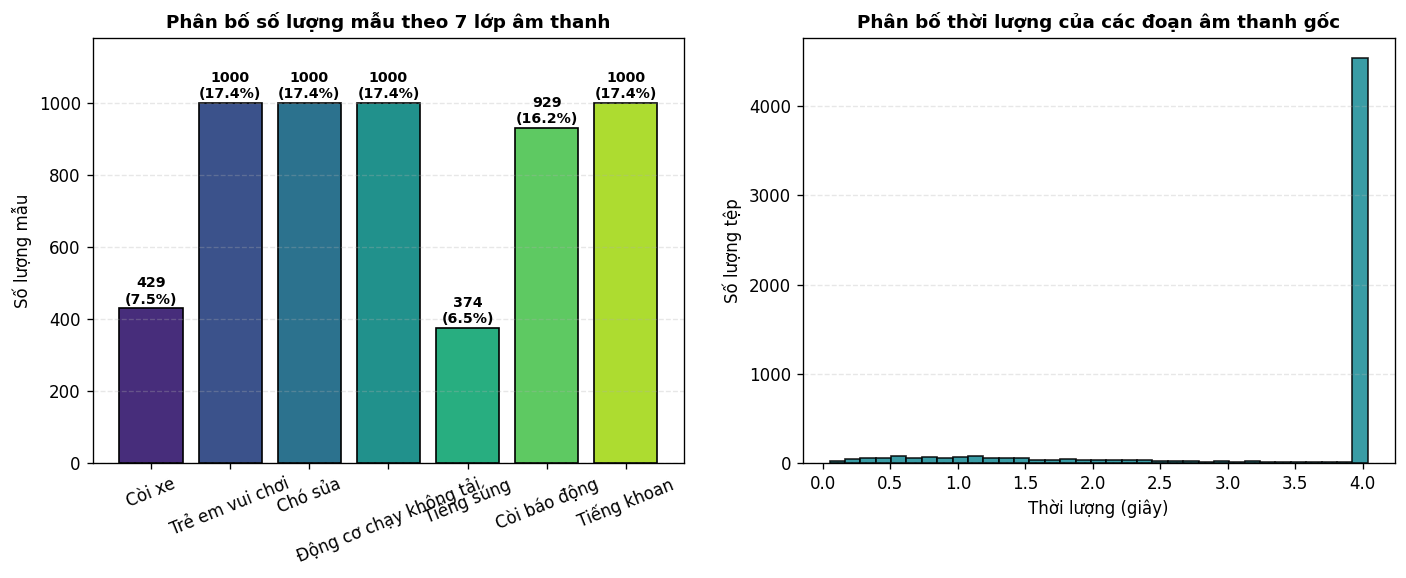

In [6]:
counts = df['class'].value_counts().reindex(CLASSES)
class_table = pd.DataFrame({
    'Nhãn gốc': CLASSES,
    'Tên tiếng Việt': VI,
    'Số lượng mẫu': counts.values,
    'Tỷ lệ (%)': (counts.values / len(df) * 100).round(2)
})
display(class_table)
class_table.to_csv(DATA_OUT_DIR / 'class_counts.csv', index=False, encoding='utf-8-sig')

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
palette = sns.color_palette('viridis', len(CLASSES))
bars = ax[0].bar(VI, counts.values, color=palette, edgecolor='black')
ax[0].tick_params(axis='x', rotation=22)
ax[0].set_title('Phân bố số lượng mẫu theo 7 lớp âm thanh', fontweight='bold')
ax[0].set_ylabel('Số lượng mẫu')
ax[0].grid(axis='y', linestyle='--', alpha=0.3)
for b, pct in zip(bars, class_table['Tỷ lệ (%)']):
    ax[0].annotate(f'{int(b.get_height())}\n({pct:.1f}%)', (b.get_x() + b.get_width()/2, b.get_height()),
                   xytext=(0, 3), textcoords='offset points', ha='center', fontsize=8.5, fontweight='bold')
ax[0].set_ylim(0, counts.max() * 1.18)

ax[1].hist(df['duration'], bins=35, color='#168b96', edgecolor='black', alpha=0.85)
ax[1].set_title('Phân bố thời lượng của các đoạn âm thanh gốc', fontweight='bold')
ax[1].set_xlabel('Thời lượng (giây)')
ax[1].set_ylabel('Số lượng tệp')
ax[1].grid(axis='y', linestyle='--', alpha=0.3)

save_fig(fig, '01_eda_distribution')
plt.show()


<a id="c3-2"></a>
## 3.2. Chuẩn hóa waveform và Log-Mel


In [7]:
def load_audio(path, sr=CFG['sr'], seconds=CFG['seconds']):
    y, orig = sf.read(str(path), always_2d=True, dtype='float32')
    if not np.isfinite(y).all():
        raise ValueError(f'Dữ liệu âm thanh chứa NaN hoặc Inf: {path}')
    y = y.mean(axis=1)
    if orig != sr:
        y = librosa.resample(y, orig_sr=orig, target_sr=sr)
    if seconds is not None:
        n = int(sr * seconds)
        if len(y) > n:
            start = (len(y) - n) // 2
            y = y[start:start + n]
        else:
            y = np.pad(y, (0, n - len(y)))
    return np.asarray(y, dtype=np.float32)

def extract_logmel_cnn(y, cfg=CFG):
    m = librosa.feature.melspectrogram(
        y=y, sr=cfg['sr'], n_fft=cfg['n_fft'], hop_length=cfg['hop_length'],
        n_mels=cfg['n_mels_cnn'], fmin=20, fmax=cfg['sr'] / 2, power=2.0
    )
    return librosa.power_to_db(m, ref=1.0, top_db=80.0).astype(np.float32)

print('Hàm chuẩn hóa tín hiệu âm thanh Mono 16kHz (4 giây) và trích xuất Log-Mel 64 bins đã sẵn sàng.')


Hàm chuẩn hóa tín hiệu âm thanh Mono 16kHz (4 giây) và trích xuất Log-Mel 64 bins đã sẵn sàng.


<a id="c3-3"></a>
## 3.3. Waveform và spectrogram mẫu


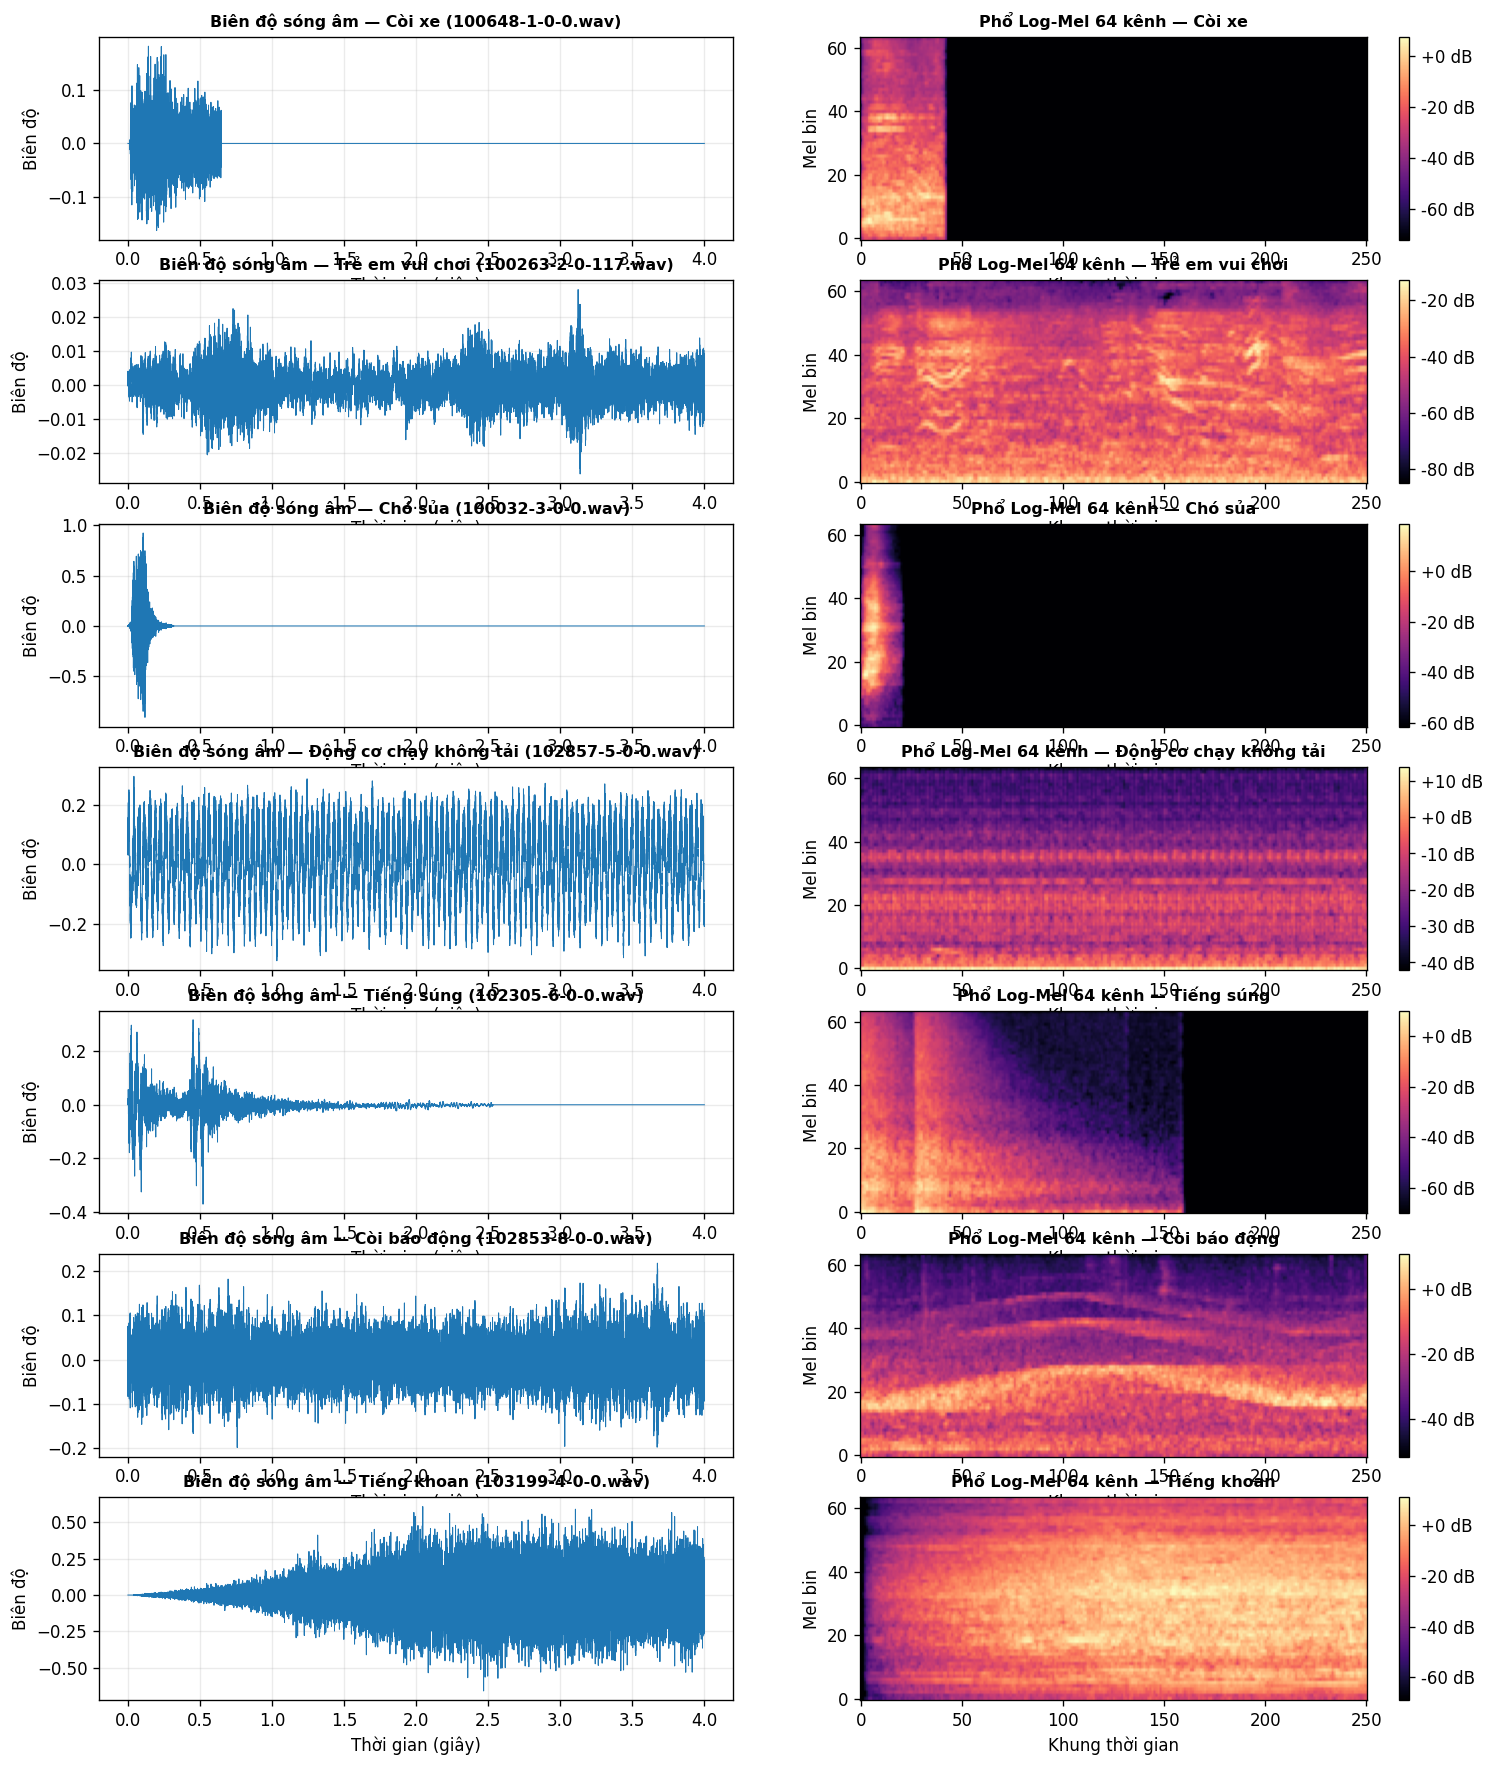

In [8]:
fig, axes = plt.subplots(7, 2, figsize=(15, 18))
for i, c in enumerate(CLASSES):
    r = df[df['class'] == c].iloc[0]
    y = load_audio(r.path, CFG['sr'], CFG['seconds'])
    m = extract_logmel_cnn(y, CFG)
    
    axes[i, 0].plot(np.arange(len(y)) / CFG['sr'], y, lw=0.6, color='#1f77b4')
    axes[i, 0].set_title(f"Biên độ sóng âm — {VI[i]} ({r.slice_file_name})", fontweight='bold', fontsize=9.5)
    axes[i, 0].set_xlabel('Thời gian (giây)')
    axes[i, 0].set_ylabel('Biên độ')
    axes[i, 0].grid(alpha=0.25)
    
    img = axes[i, 1].imshow(m, origin='lower', aspect='auto', cmap='magma')
    axes[i, 1].set_title(f"Phổ Log-Mel 64 kênh — {VI[i]}", fontweight='bold', fontsize=9.5)
    axes[i, 1].set_xlabel('Khung thời gian')
    axes[i, 1].set_ylabel('Mel bin')
    plt.colorbar(img, ax=axes[i, 1], format='%+2.0f dB')

save_fig(fig, '02_eda_waveform_logmel')
plt.show()


<a id="chia-tap"></a>
# 4. Chia tập và kiểm soát rò rỉ

<a id="c4-1"></a>
## 4.1. Chia theo nhóm fsID


,test_fold,val_fold,train_samples,val_samples,test_samples,purged_from_val,purged_from_train
0,10,1,4632,553,541,0,6


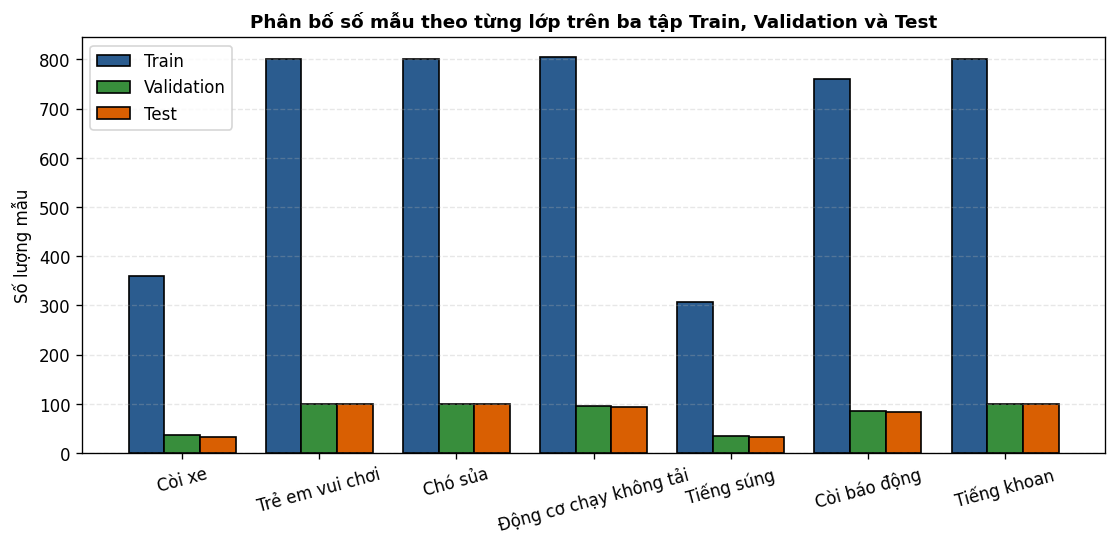

In [9]:
def make_clean_splits(df, test_fold=10, val_fold=1, cfg=CFG, root=ROOT):
    test = df[df['fold'] == test_fold].copy()
    val_raw = df[df['fold'] == val_fold].copy()
    train_raw = df[~df['fold'].isin([test_fold, val_fold])].copy()
    
    # Purge mẫu trùng nguồn âm (group = source_id U sha256) theo ưu tiên: Test > Validation > Train
    val = val_raw[~val_raw['group'].isin(set(test['group']))].copy()
    used_groups = set(test['group']).union(set(val['group']))
    train = train_raw[~train_raw['group'].isin(used_groups)].copy()
    
    assert set(train['group']).isdisjoint(set(val['group'])), "Rò rỉ nhóm nguồn âm giữa Train và Val!"
    assert set(train['group']).isdisjoint(set(test['group'])), "Rò rỉ nhóm nguồn âm giữa Train và Test!"
    assert set(val['group']).isdisjoint(set(test['group'])), "Rò rỉ nhóm nguồn âm giữa Val và Test!"
    
    rep = {
        'test_fold': int(test_fold),
        'val_fold': int(val_fold),
        'train_samples': len(train),
        'val_samples': len(val),
        'test_samples': len(test),
        'purged_from_val': len(val_raw) - len(val),
        'purged_from_train': len(train_raw) - len(train)
    }
    dump_json(rep, DATA_OUT_DIR / f'split_fold{test_fold}.json')
    return train.reset_index(drop=True), val.reset_index(drop=True), test.reset_index(drop=True), rep

train_df, val_df, test_df, split_rep = make_clean_splits(df, CFG['test_fold'], CFG['val_fold'])
display(pd.DataFrame([split_rep]))

split_dist = pd.DataFrame({
    'Lớp âm thanh': VI,
    'Train': [int((train_df['label'] == i).sum()) for i in range(7)],
    'Validation': [int((val_df['label'] == i).sum()) for i in range(7)],
    'Test': [int((test_df['label'] == i).sum()) for i in range(7)]
})
split_dist.to_csv(DATA_OUT_DIR / 'split_class_distribution.csv', index=False)

fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(VI))
w = 0.26
ax.bar(x - w, split_dist['Train'], width=w, label='Train', color='#2b5c8f', edgecolor='black')
ax.bar(x, split_dist['Validation'], width=w, label='Validation', color='#388e3c', edgecolor='black')
ax.bar(x + w, split_dist['Test'], width=w, label='Test', color='#d95f02', edgecolor='black')
ax.set_xticks(x); ax.set_xticklabels(VI, rotation=15)
ax.set_title('Phân bố số mẫu theo từng lớp trên ba tập Train, Validation và Test', fontweight='bold')
ax.set_ylabel('Số lượng mẫu'); ax.legend(); ax.grid(axis='y', linestyle='--', alpha=0.3)
save_fig(fig, '03_split_distribution_by_class')
plt.show()


<a id="c4-2"></a>
## 4.2. Per-Bin Z-score


preprocessor_config.json:   0%|          | 0.00/297 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/26.8k [00:00<?, ?B/s]

Đã tải cấu hình AST thành công từ: MIT/ast-finetuned-audioset-10-10-0.4593
Kích thước đầu vào AST (max_length, num_mel_bins): (1024, 128)


Trích xuất và lưu cache Log-Mel 64 cho CNN:   0%|          | 0/5732 [00:00<?, ?it/s]

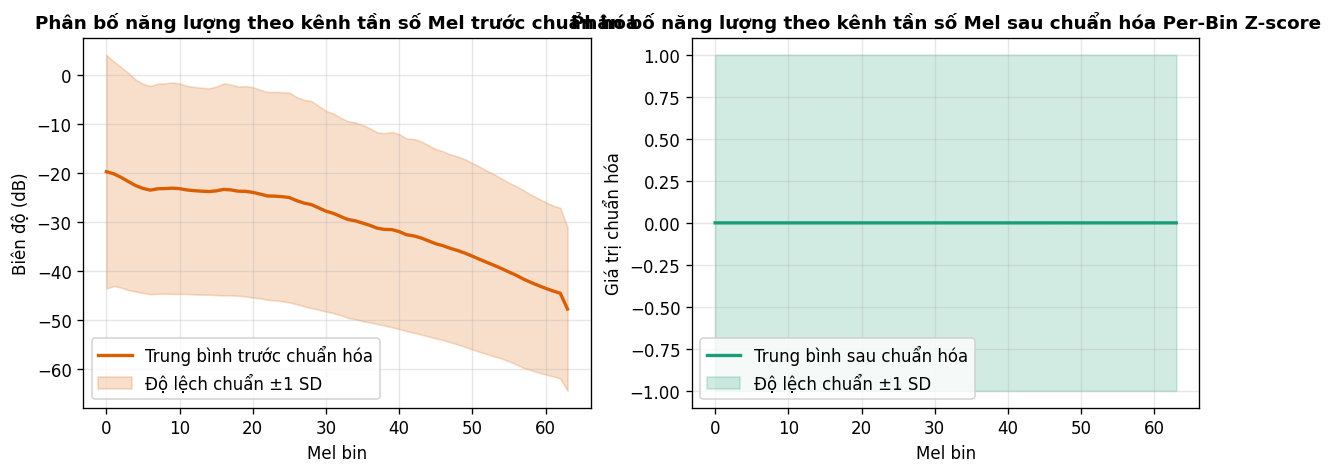

In [10]:
# Khởi tạo bộ xử lý đặc trưng cho AST Pretrained và bộ nhớ đệm Log-Mel cho CNN
def resolve_ast_source(cfg=CFG):
    if cfg['ast_local_path'] and Path(cfg['ast_local_path']).exists():
        return cfg['ast_local_path'], True
    return cfg['ast_id'], False

AST_SOURCE, AST_LOCAL = resolve_ast_source(CFG)
ast_fe = AutoFeatureExtractor.from_pretrained(AST_SOURCE, local_files_only=AST_LOCAL)
ast_cfg = AutoConfig.from_pretrained(AST_SOURCE, local_files_only=AST_LOCAL)
print('Đã tải cấu hình AST thành công từ:', AST_SOURCE)
print('Kích thước đầu vào AST (max_length, num_mel_bins):', (ast_fe.max_length, ast_fe.num_mel_bins))

# Tính và lưu cache Log-Mel 64 bins cho CNN
CNN_CACHE_DIR = ROOT / 'cache/logmel64'
CNN_CACHE_DIR.mkdir(parents=True, exist_ok=True)

for r in tqdm(df.itertuples(), total=len(df), desc='Trích xuất và lưu cache Log-Mel 64 cho CNN'):
    cp = CNN_CACHE_DIR / f'{r.sha256}.npy'
    if not cp.exists():
        np.save(cp, extract_logmel_cnn(load_audio(r.path, CFG['sr'], CFG['seconds']), CFG))

train_specs = np.stack([np.load(CNN_CACHE_DIR / f'{s}.npy') for s in train_df['sha256']])
CNN_MEAN = train_specs.mean(axis=(0, 2), keepdims=True).astype(np.float32)
CNN_STD = (train_specs.std(axis=(0, 2), keepdims=True) + 1e-6).astype(np.float32)
np.savez(DATA_OUT_DIR / f"cnn_norm_fold{CFG['test_fold']}.npz", mean=CNN_MEAN, std=CNN_STD)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(train_specs.mean(axis=(0, 2)), color='#d95f02', lw=2, label='Trung bình trước chuẩn hóa')
axes[0].fill_between(range(64),
                     train_specs.mean(axis=(0, 2)) - train_specs.std(axis=(0, 2)),
                     train_specs.mean(axis=(0, 2)) + train_specs.std(axis=(0, 2)),
                     color='#d95f02', alpha=0.2, label='Độ lệch chuẩn ±1 SD')
axes[0].set_title('Phân bố năng lượng theo kênh tần số Mel trước chuẩn hóa', fontweight='bold')
axes[0].set_xlabel('Mel bin'); axes[0].set_ylabel('Biên độ (dB)'); axes[0].legend(); axes[0].grid(alpha=0.3)

norm_sample = (train_specs - CNN_MEAN) / CNN_STD
axes[1].plot(norm_sample.mean(axis=(0, 2)), color='#1b9e77', lw=2, label='Trung bình sau chuẩn hóa')
axes[1].fill_between(range(64),
                     norm_sample.mean(axis=(0, 2)) - norm_sample.std(axis=(0, 2)),
                     norm_sample.mean(axis=(0, 2)) + norm_sample.std(axis=(0, 2)),
                     color='#1b9e77', alpha=0.2, label='Độ lệch chuẩn ±1 SD')
axes[1].set_title('Phân bố năng lượng theo kênh tần số Mel sau chuẩn hóa Per-Bin Z-score', fontweight='bold')
axes[1].set_xlabel('Mel bin'); axes[1].set_ylabel('Giá trị chuẩn hóa'); axes[1].legend(); axes[1].grid(alpha=0.3)
del train_specs, norm_sample
gc.collect()

save_fig(fig, '04_per_bin_zscore_normalization')
plt.show()


<a id="c4-3"></a>
## 4.3. Dataset và DataLoader


In [11]:
class MelDataset(Dataset):
    def __init__(self, d, cache_dir, mean, std, train=False, seed=42):
        self.d = d.reset_index(drop=True)
        self.cache_dir = Path(cache_dir)
        self.mean = mean
        self.std = std
        self.train = train
        self.seed = seed
        self.epoch = 0

    def set_epoch(self, e):
        self.epoch = int(e)

    def __len__(self):
        return len(self.d)

    def __getitem__(self, idx):
        r = self.d.iloc[idx]
        x = (np.load(self.cache_dir / f'{r.sha256}.npy').astype(np.float32) - self.mean[:, 0, :]) / self.std[:, 0, :]
        if self.train:
            rng = np.random.default_rng(self.seed + self.epoch * 100000 + idx)
            x = x.copy()
            F_bins, T_frames = x.shape
            if rng.random() < 0.5:
                fw = int(rng.integers(1, 7))
                f0 = int(rng.integers(0, F_bins - fw))
                x[f0:f0 + fw, :] = 0.0
            if rng.random() < 0.5:
                tw = int(rng.integers(1, 20))
                t0 = int(rng.integers(0, T_frames - tw))
                x[:, t0:t0 + tw] = 0.0
        return {'x': torch.from_numpy(x)[None, ...], 'y': torch.tensor(int(r.label), dtype=torch.long), 'file': r.slice_file_name}

class ASTDataset(Dataset):
    def __init__(self, d, fe, cfg=CFG, train=False, seed=42):
        self.d = d.reset_index(drop=True)
        self.fe = fe
        self.cfg = cfg
        self.train = train
        self.seed = seed
        self.epoch = 0

    def set_epoch(self, e):
        self.epoch = int(e)

    def __len__(self):
        return len(self.d)

    def __getitem__(self, idx):
        r = self.d.iloc[idx]
        y = load_audio(r.path, self.cfg['sr'], self.cfg['seconds'])
        if self.train:
            rng = np.random.default_rng(self.seed + self.epoch * 100000 + idx)
            y = np.roll(y, int(rng.integers(-1200, 1201))) * float(10 ** (rng.uniform(-3, 3) / 20))
            if rng.random() < 0.3:
                y = y + rng.normal(0, 0.002, size=y.shape).astype(np.float32)
            y = np.clip(y, -1.0, 1.0)
        v = self.fe(y, sampling_rate=self.cfg['sr'], return_tensors='pt')['input_values'].squeeze(0)
        if self.train:
            rng = np.random.default_rng(self.seed + 500000 + self.epoch * 100000 + idx)
            v = v.clone()
            t = int(rng.integers(0, 32))
            t0 = int(rng.integers(0, max(1, v.shape[0] - t)))
            v[t0:t0 + t, :] = 0
            f = int(rng.integers(0, 12))
            f0 = int(rng.integers(0, max(1, v.shape[1] - f)))
            v[:, f0:f0 + f] = 0
        return {'x': v, 'y': torch.tensor(int(r.label), dtype=torch.long), 'file': r.slice_file_name}

print('Đã khởi tạo MelDataset (cho CNN 4 khối & ResCNN) và ASTDataset (cho AST Pretrained).')


Đã khởi tạo MelDataset (cho CNN 4 khối & ResCNN) và ASTDataset (cho AST Pretrained).


<a id="mo-hinh"></a>
# 5. Các mô hình phân loại

<a id="c5-1"></a>
## 5.1. Custom 2D-CNN tự xây dựng


In [12]:
class CustomCNN4(nn.Module):
    """Mô hình CNN 4 khối tích chập tự xây dựng và cộng sự (2022)."""
    def __init__(self, num_classes=7):
        super().__init__()
        def block(cin, cout, drop):
            return nn.Sequential(
                nn.Conv2d(cin, cout, 3, padding=1, bias=False),
                nn.BatchNorm2d(cout),
                nn.ReLU(inplace=True),
                nn.Conv2d(cout, cout, 3, padding=1, bias=False),
                nn.BatchNorm2d(cout),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(2),
                nn.Dropout2d(drop)
            )
        self.features = nn.Sequential(
            block(1, 32, 0.10),
            block(32, 64, 0.15),
            block(64, 128, 0.20),
            block(128, 256, 0.25)
        )
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.35),
            nn.Linear(128, num_classes)
        )

    def forward_features(self, x):
        return self.pool(self.features(x)).flatten(1)

    def forward(self, x):
        return self.head(self.pool(self.features(x)))


<a id="c5-2"></a>
## 5.2. Custom ResAttention-CNN


In [13]:
class ResBlock(nn.Module):
    def __init__(self, cin, cout, stride=1, drop=0.15):
        super().__init__()
        self.c1 = nn.Conv2d(cin, cout, 3, stride=stride, padding=1, bias=False)
        self.b1 = nn.BatchNorm2d(cout)
        self.c2 = nn.Conv2d(cout, cout, 3, padding=1, bias=False)
        self.b2 = nn.BatchNorm2d(cout)
        self.se = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(cout, max(cout // 8, 4), 1),
            nn.ReLU(inplace=True),
            nn.Conv2d(max(cout // 8, 4), cout, 1),
            nn.Sigmoid()
        )
        self.drop = nn.Dropout2d(drop)
        self.short = nn.Identity() if (cin == cout and stride == 1) else nn.Sequential(
            nn.Conv2d(cin, cout, 1, stride=stride, bias=False),
            nn.BatchNorm2d(cout)
        )

    def forward(self, x):
        out = F.gelu(self.b1(self.c1(x)))
        out = self.b2(self.c2(out))
        out = out * self.se(out)
        out = self.drop(out)
        return F.gelu(out + self.short(x))

class CustomResCNN(nn.Module):
    """Mô hình CNN Residual tự xây dựng tích hợp cơ chế chú ý kênh Squeeze-and-Excitation."""
    def __init__(self, num_classes=7):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.GELU()
        )
        self.s1 = ResBlock(32, 64, 2, 0.10)
        self.s2 = ResBlock(64, 128, 2, 0.15)
        self.s3 = ResBlock(128, 256, 2, 0.20)
        self.s4 = ResBlock(256, 256, 2, 0.25)
        self.head = nn.Sequential(
            nn.LayerNorm(512),
            nn.Dropout(0.35),
            nn.Linear(512, 128),
            nn.GELU(),
            nn.Dropout(0.25),
            nn.Linear(128, num_classes)
        )

    def forward_features(self, x):
        x = self.s4(self.s3(self.s2(self.s1(self.stem(x)))))
        return torch.cat([x.mean((-2, -1)), x.amax((-2, -1))], dim=1)

    def forward(self, x):
        feat = self.forward_features(x)
        return self.head(feat)


<a id="c5-3"></a>
## 5.3. Các mô hình pretrained


In [14]:
class ASTClassifier(nn.Module):
    """Mô hình Audio Spectrogram Transformer (AST) Pretrained trên AudioSet, fine-tune cho 7 lớp âm thanh đô thị."""
    def __init__(self, source, local_only=False, num_classes=7, gradient_checkpointing=True):
        super().__init__()
        id2label = {i: c for i, c in enumerate(CLASSES)}
        label2id = {c: i for i, c in enumerate(CLASSES)}
        self.model = ASTForAudioClassification.from_pretrained(
            source,
            num_labels=num_classes,
            id2label=id2label,
            label2id=label2id,
            ignore_mismatched_sizes=True,
            local_files_only=local_only
        )
        if gradient_checkpointing and hasattr(self.model, 'gradient_checkpointing_enable'):
            self.model.gradient_checkpointing_enable()

    def forward_features(self, x):
        outputs = self.model.audio_spectrogram_transformer(x)
        return outputs.pooler_output

    def forward(self, x):
        return self.model(x).logits

def build_model(key, cfg=CFG):
    if key == 'cnn4':
        return CustomCNN4(num_classes=len(CLASSES))
    if key == 'rescnn':
        return CustomResCNN(num_classes=len(CLASSES))
    if key == 'ast':
        return ASTClassifier(AST_SOURCE, AST_LOCAL, num_classes=len(CLASSES), gradient_checkpointing=cfg['gradient_checkpointing'])
    raise ValueError(f'Không nhận diện được mã mô hình: {key}')

print('Đã định nghĩa 3 kiến trúc mô hình cốt lõi:', [MODEL_NAMES[k] for k in CFG['models']])


Đã định nghĩa 3 kiến trúc mô hình cốt lõi: ['CNN 4 khối', 'ResCNN tự xây dựng', 'AST Pretrained']


<a id="huan-luyen"></a>
# 6. Huấn luyện, transfer learning và fine-tuning

<a id="c6-1"></a>
## 6.1. Hàm đánh giá và optimizer


In [15]:
def compute_metrics_from_probs(y_true, prob):
    pred = prob.argmax(axis=1)
    acc = float(accuracy_score(y_true, pred))
    mp, mr, mf1, _ = precision_recall_fscore_support(y_true, pred, average='macro', zero_division=0)
    wp, wr, wf1, _ = precision_recall_fscore_support(y_true, pred, average='weighted', zero_division=0)
    p, r, f1, sup = precision_recall_fscore_support(y_true, pred, labels=range(7), zero_division=0)
    return {
        'accuracy': acc,
        'macro_precision': float(mp),
        'macro_recall': float(mr),
        'macro_f1': float(mf1),
        'weighted_f1': float(wf1),
        'per_class': pd.DataFrame({
            'class': CLASSES, 'label_vi': VI,
            'precision': p, 'recall': r, 'f1': f1, 'support': sup
        })
    }

@torch.no_grad()
def evaluate_loader(model, loader, device, criterion, amp=True):
    model.eval()
    losses, probs, ys, files = [], [], [], []
    use_amp = bool(amp and device.type == 'cuda')
    for b in loader:
        x = b['x'].to(device)
        y = b['y'].to(device)
        ctx = torch.amp.autocast('cuda', dtype=torch.float16) if use_amp else nullcontext()
        with ctx:
            logits = model(x)
            loss = criterion(logits, y)
        losses.append(float(loss.item()) * len(y))
        probs.append(torch.softmax(logits.float(), dim=-1).cpu().numpy())
        ys.append(y.cpu().numpy())
        files.extend(b['file'])
    prob = np.concatenate(probs)
    y_true = np.concatenate(ys)
    m = compute_metrics_from_probs(y_true, prob)
    m['loss'] = float(np.sum(losses) / len(y_true))
    return m, prob, y_true, files


<a id="c6-2"></a>
## 6.2. Huấn luyện và chọn theo Validation


In [16]:
def train_model_pipeline(key, train_df, val_df, test_df, cfg=CFG, device=DEVICE):
    seed_all(cfg['seed'])
    is_ast = (key == 'ast')
    epochs = (1 if cfg['mode'] == 'smoke' else (cfg['ast_epochs'] if is_ast else cfg['cnn_epochs']))
    bs = cfg['ast_batch'] if is_ast else cfg['cnn_batch']
    accum = cfg['ast_accum'] if is_ast else 1
    lr = cfg['ast_lr'] if is_ast else cfg['cnn_lr']

    if is_ast:
        tr_ds = ASTDataset(train_df, ast_fe, cfg, train=True, seed=cfg['seed'])
        va_ds = ASTDataset(val_df, ast_fe, cfg, train=False, seed=cfg['seed'])
        te_ds = ASTDataset(test_df, ast_fe, cfg, train=False, seed=cfg['seed'])
    else:
        tr_ds = MelDataset(train_df, CNN_CACHE_DIR, CNN_MEAN, CNN_STD, train=True, seed=cfg['seed'])
        va_ds = MelDataset(val_df, CNN_CACHE_DIR, CNN_MEAN, CNN_STD, train=False, seed=cfg['seed'])
        te_ds = MelDataset(test_df, CNN_CACHE_DIR, CNN_MEAN, CNN_STD, train=False, seed=cfg['seed'])

    tr_loader = DataLoader(tr_ds, batch_size=bs, shuffle=True, num_workers=0, pin_memory=(device.type == 'cuda'))
    va_loader = DataLoader(va_ds, batch_size=bs, shuffle=False, num_workers=0, pin_memory=(device.type == 'cuda'))
    te_loader = DataLoader(te_ds, batch_size=bs, shuffle=False, num_workers=0, pin_memory=(device.type == 'cuda'))

    model = build_model(key, cfg).to(device)
    counts = train_df['label'].value_counts().reindex(range(7)).values.astype(np.float32)
    weights = torch.tensor(counts.sum() / (7.0 * counts), dtype=torch.float32, device=device)
    criterion = nn.CrossEntropyLoss(weight=weights, label_smoothing=0.06)

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=cfg['weight_decay'])
    total_steps = max(1, epochs * math.ceil(len(tr_loader) / accum))
    warmup_steps = max(1, int(0.1 * total_steps))
    def lr_lambda(step):
        if step < warmup_steps:
            return float(step + 1) / float(warmup_steps)
        prog = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1.0 + math.cos(math.pi * min(1.0, prog)))
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

    use_amp = bool(cfg['amp'] and device.type == 'cuda')
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

    best_path = CHECKPOINT_DIR / f'{key}_best.pt'
    hist = []
    best_f1 = -1.0
    best_epoch = 0
    bad_epochs = 0
    t_train_start = time.perf_counter()

    for ep in range(1, epochs + 1):
        ep_t0 = time.perf_counter()
        tr_ds.set_epoch(ep)
        model.train()
        optimizer.zero_grad(set_to_none=True)
        losses, probs, ys = [], [], []
        current_lr = optimizer.param_groups[0]['lr']

        pbar = tqdm(enumerate(tr_loader, 1), total=len(tr_loader), leave=False, desc=f"{MODEL_NAMES[key]} Epoch {ep}/{epochs}")
        for step, b in pbar:
            x = b['x'].to(device)
            y = b['y'].to(device)
            ctx = torch.amp.autocast('cuda', dtype=torch.float16) if use_amp else nullcontext()
            with ctx:
                logits = model(x)
                loss = criterion(logits, y)
            scaler.scale(loss / accum).backward()
            if step % accum == 0 or step == len(tr_loader):
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad(set_to_none=True)
                scheduler.step()

            losses.append(float(loss.item()) * len(y))
            probs.append(torch.softmax(logits.detach().float(), dim=-1).cpu().numpy())
            ys.append(y.cpu().numpy())

        tr_prob = np.concatenate(probs)
        tr_y = np.concatenate(ys)
        tr_m = compute_metrics_from_probs(tr_y, tr_prob)
        tr_loss = float(np.sum(losses) / len(tr_y))

        va_m, _, _, _ = evaluate_loader(model, va_loader, device, criterion, cfg['amp'])
        ep_sec = time.perf_counter() - ep_t0

        row = {
            'epoch': ep,
            'lr': current_lr,
            'train_loss': tr_loss,
            'val_loss': va_m['loss'],
            'train_acc': tr_m['accuracy'],
            'val_acc': va_m['accuracy'],
            'train_f1': tr_m['macro_f1'],
            'val_f1': va_m['macro_f1'],
            'gap_acc': tr_m['accuracy'] - va_m['accuracy'],
            'gap_loss': va_m['loss'] - tr_loss,
            'seconds': ep_sec
        }
        hist.append(row)
        print(f"  Epoch {ep:02d}/{epochs:02d} — Train Loss: {tr_loss:.4f}, Val Loss: {va_m['loss']:.4f} | Train Acc: {tr_m['accuracy']*100:.1f}%, Val Acc: {va_m['accuracy']*100:.1f}% | Val Macro-F1: {va_m['macro_f1']*100:.2f}% ({ep_sec:.1f}s)")

        if va_m['macro_f1'] > best_f1:
            best_f1 = va_m['macro_f1']
            best_epoch = ep
            bad_epochs = 0
            torch.save({'model': model.state_dict(), 'best_f1': best_f1, 'best_epoch': best_epoch}, best_path)
        else:
            bad_epochs += 1
            if bad_epochs >= cfg['patience']:
                print(f"  --> Dừng sớm tại Epoch {ep} (Epoch tối ưu: {best_epoch}, Val Macro-F1 đạt: {best_f1*100:.2f}%)")
                break

    total_train_time = time.perf_counter() - t_train_start
    ckpt = torch.load(best_path, map_location=device, weights_only=True)
    model.load_state_dict(ckpt['model'])

    hist_df = pd.DataFrame(hist)
    hist_df['best_epoch'] = best_epoch
    hist_df['total_train_time_s'] = total_train_time
    hist_df.to_csv(LOGS_DIR / f'{key}_history.csv', index=False)

    va_m, va_prob, va_y, va_files = evaluate_loader(model, va_loader, device, criterion, cfg['amp'])
    te_m, te_prob, te_y, te_files = evaluate_loader(model, te_loader, device, criterion, cfg['amp'])

    return {
        'key': key,
        'name': MODEL_NAMES[key],
        'model': model,
        'ckpt_path': best_path,
        'history': hist_df,
        'best_epoch': best_epoch,
        'total_train_time_s': total_train_time,
        'val_metrics': va_m, 'val_prob': va_prob, 'val_y': va_y, 'val_files': va_files,
        'test_metrics': te_m, 'test_prob': te_prob, 'test_y': te_y, 'test_files': te_files,
        'test_loader': te_loader
    }

RUNS = OrderedDict()
for k in CFG['models']:
    print(f"\n=======================================================")
    print(f"BẮT ĐẦU HUẤN LUYỆN MÔ HÌNH: {MODEL_NAMES[k].upper()}")
    print(f"=======================================================")
    RUNS[k] = train_model_pipeline(k, train_df, val_df, test_df, CFG, DEVICE)



BẮT ĐẦU HUẤN LUYỆN MÔ HÌNH: CNN 4 KHỐI


CNN 4 khối Epoch 1/45:   0%|          | 0/290 [00:00<?, ?it/s]

  Epoch 01/45 — Train Loss: 1.7507, Val Loss: 1.4514 | Train Acc: 33.1%, Val Acc: 58.6% | Val Macro-F1: 56.45% (9.8s)


CNN 4 khối Epoch 2/45:   0%|          | 0/290 [00:00<?, ?it/s]

  Epoch 02/45 — Train Loss: 1.3542, Val Loss: 1.0553 | Train Acc: 54.9%, Val Acc: 67.3% | Val Macro-F1: 66.91% (7.0s)


...

  Epoch 10/12 — Train Loss: 0.3545, Val Loss: 0.4441 | Train Acc: 100.0%, Val Acc: 97.1% | Val Macro-F1: 97.28% (449.7s)


AST Pretrained Epoch 11/12:   0%|          | 0/2316 [00:00<?, ?it/s]

  Epoch 11/12 — Train Loss: 0.3545, Val Loss: 0.4354 | Train Acc: 100.0%, Val Acc: 97.6% | Val Macro-F1: 97.85% (449.7s)


AST Pretrained Epoch 12/12:   0%|          | 0/2316 [00:00<?, ?it/s]

  Epoch 12/12 — Train Loss: 0.3530, Val Loss: 0.4389 | Train Acc: 100.0%, Val Acc: 97.6% | Val Macro-F1: 97.85% (446.7s)


<a id="c6-3"></a>
## 6.3. Learning curves so sánh


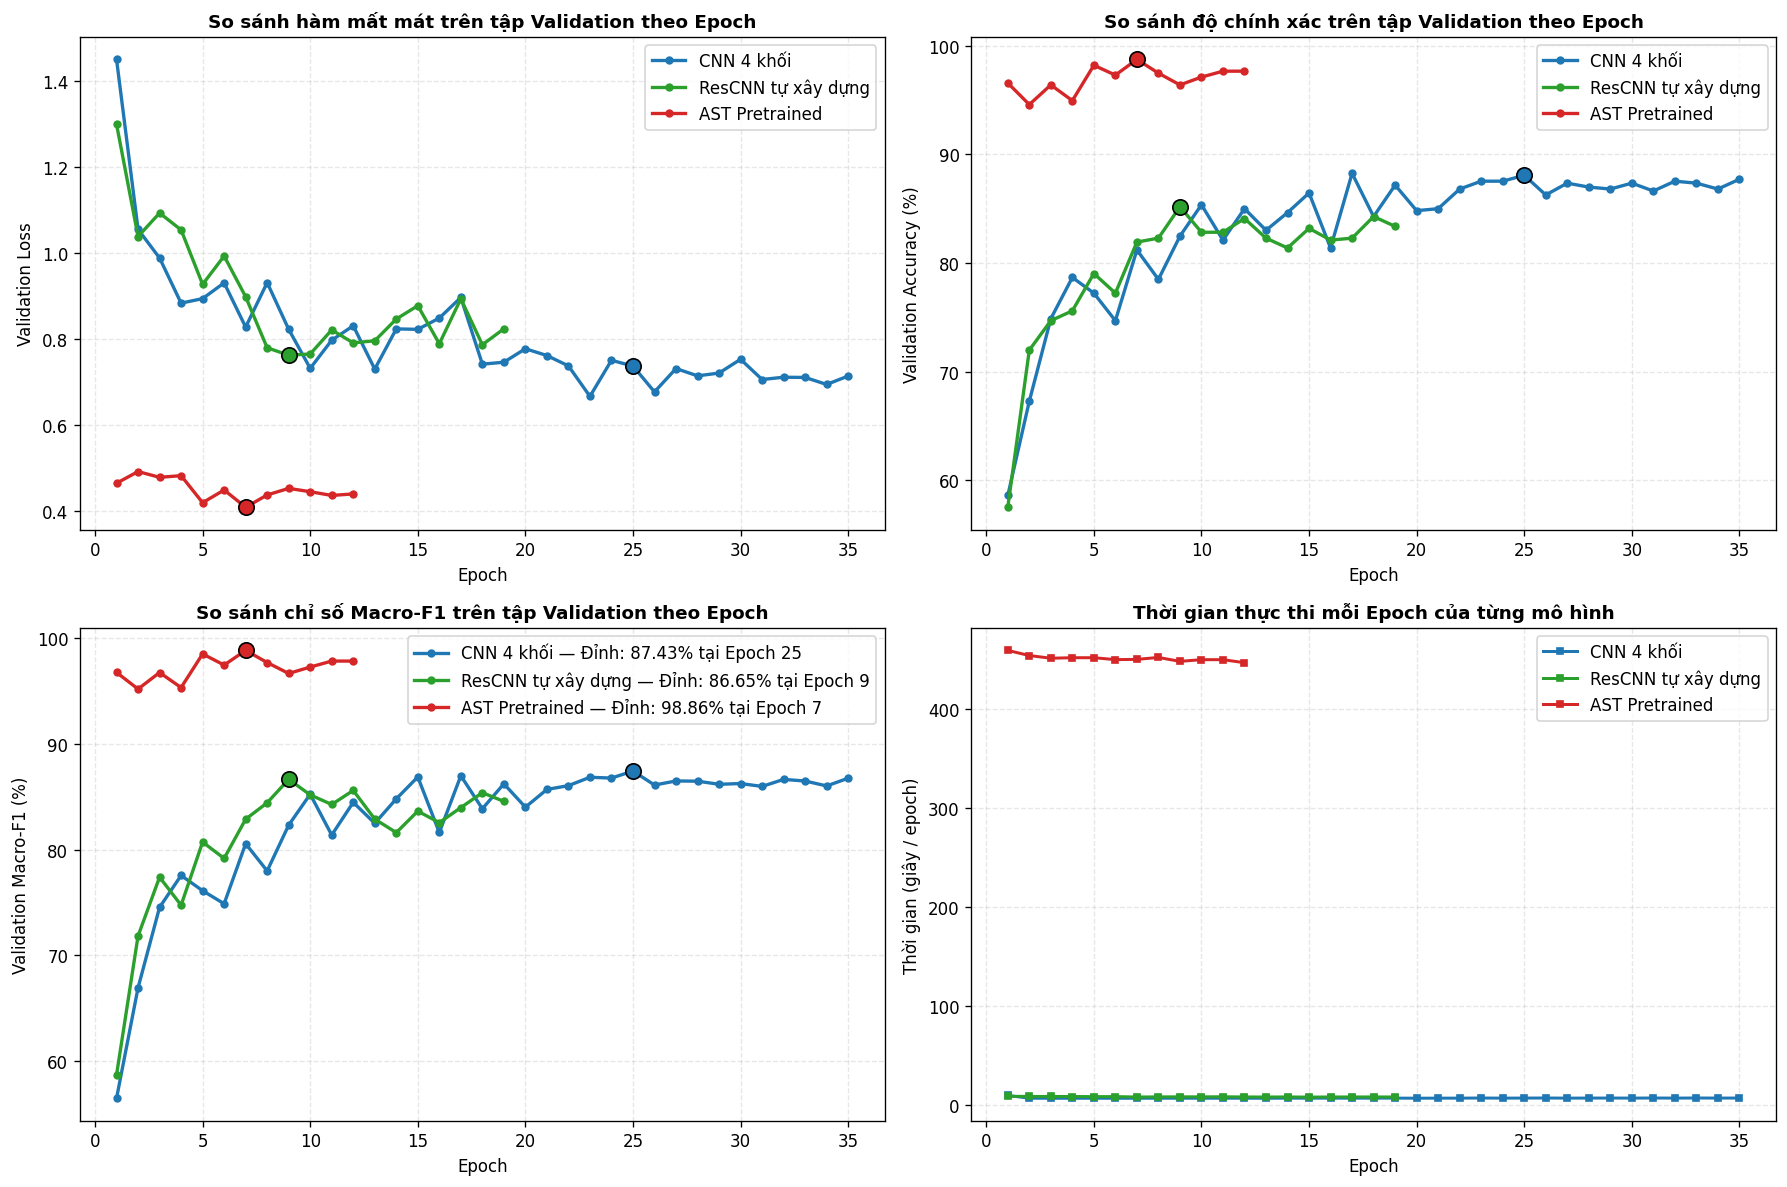

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
colors = {'cnn4': '#1f77b4', 'rescnn': '#2ca02c', 'ast': '#d62728'}

for k, r in RUNS.items():
    hdf = r['history']
    c = colors.get(k, '#9467bd')
    b_ep = r['best_epoch']
    b_row = hdf[hdf['epoch'] == b_ep].iloc[0]

    axes[0, 0].plot(hdf['epoch'], hdf['val_loss'], marker='o', markersize=4, lw=2, color=c, label=r['name'])
    axes[0, 0].scatter(b_ep, b_row['val_loss'], s=85, color=c, edgecolors='black', zorder=5)

    axes[0, 1].plot(hdf['epoch'], hdf['val_acc'] * 100, marker='o', markersize=4, lw=2, color=c, label=r['name'])
    axes[0, 1].scatter(b_ep, b_row['val_acc'] * 100, s=85, color=c, edgecolors='black', zorder=5)

    axes[1, 0].plot(hdf['epoch'], hdf['val_f1'] * 100, marker='o', markersize=4, lw=2, color=c,
                    label=f"{r['name']} — Đỉnh: {b_row['val_f1']*100:.2f}% tại Epoch {b_ep}")
    axes[1, 0].scatter(b_ep, b_row['val_f1'] * 100, s=85, color=c, edgecolors='black', zorder=5)

    axes[1, 1].plot(hdf['epoch'], hdf['seconds'], marker='s', markersize=3.5, lw=1.8, color=c, label=r['name'])

axes[0, 0].set_title('So sánh hàm mất mát trên tập Validation theo Epoch', fontweight='bold')
axes[0, 0].set_xlabel('Epoch'); axes[0, 0].set_ylabel('Validation Loss'); axes[0, 0].grid(linestyle='--', alpha=0.3); axes[0, 0].legend()

axes[0, 1].set_title('So sánh độ chính xác trên tập Validation theo Epoch', fontweight='bold')
axes[0, 1].set_xlabel('Epoch'); axes[0, 1].set_ylabel('Validation Accuracy (%)'); axes[0, 1].grid(linestyle='--', alpha=0.3); axes[0, 1].legend()

axes[1, 0].set_title('So sánh chỉ số Macro-F1 trên tập Validation theo Epoch', fontweight='bold')
axes[1, 0].set_xlabel('Epoch'); axes[1, 0].set_ylabel('Validation Macro-F1 (%)'); axes[1, 0].grid(linestyle='--', alpha=0.3); axes[1, 0].legend()

axes[1, 1].set_title('Thời gian thực thi mỗi Epoch của từng mô hình', fontweight='bold')
axes[1, 1].set_xlabel('Epoch'); axes[1, 1].set_ylabel('Thời gian (giây / epoch)'); axes[1, 1].grid(linestyle='--', alpha=0.3); axes[1, 1].legend()

plt.tight_layout()
save_fig(fig, '05_learning_curves_comparison')
plt.show()


<a id="c6-4"></a>
## 6.4. Đường cong riêng từng mô hình


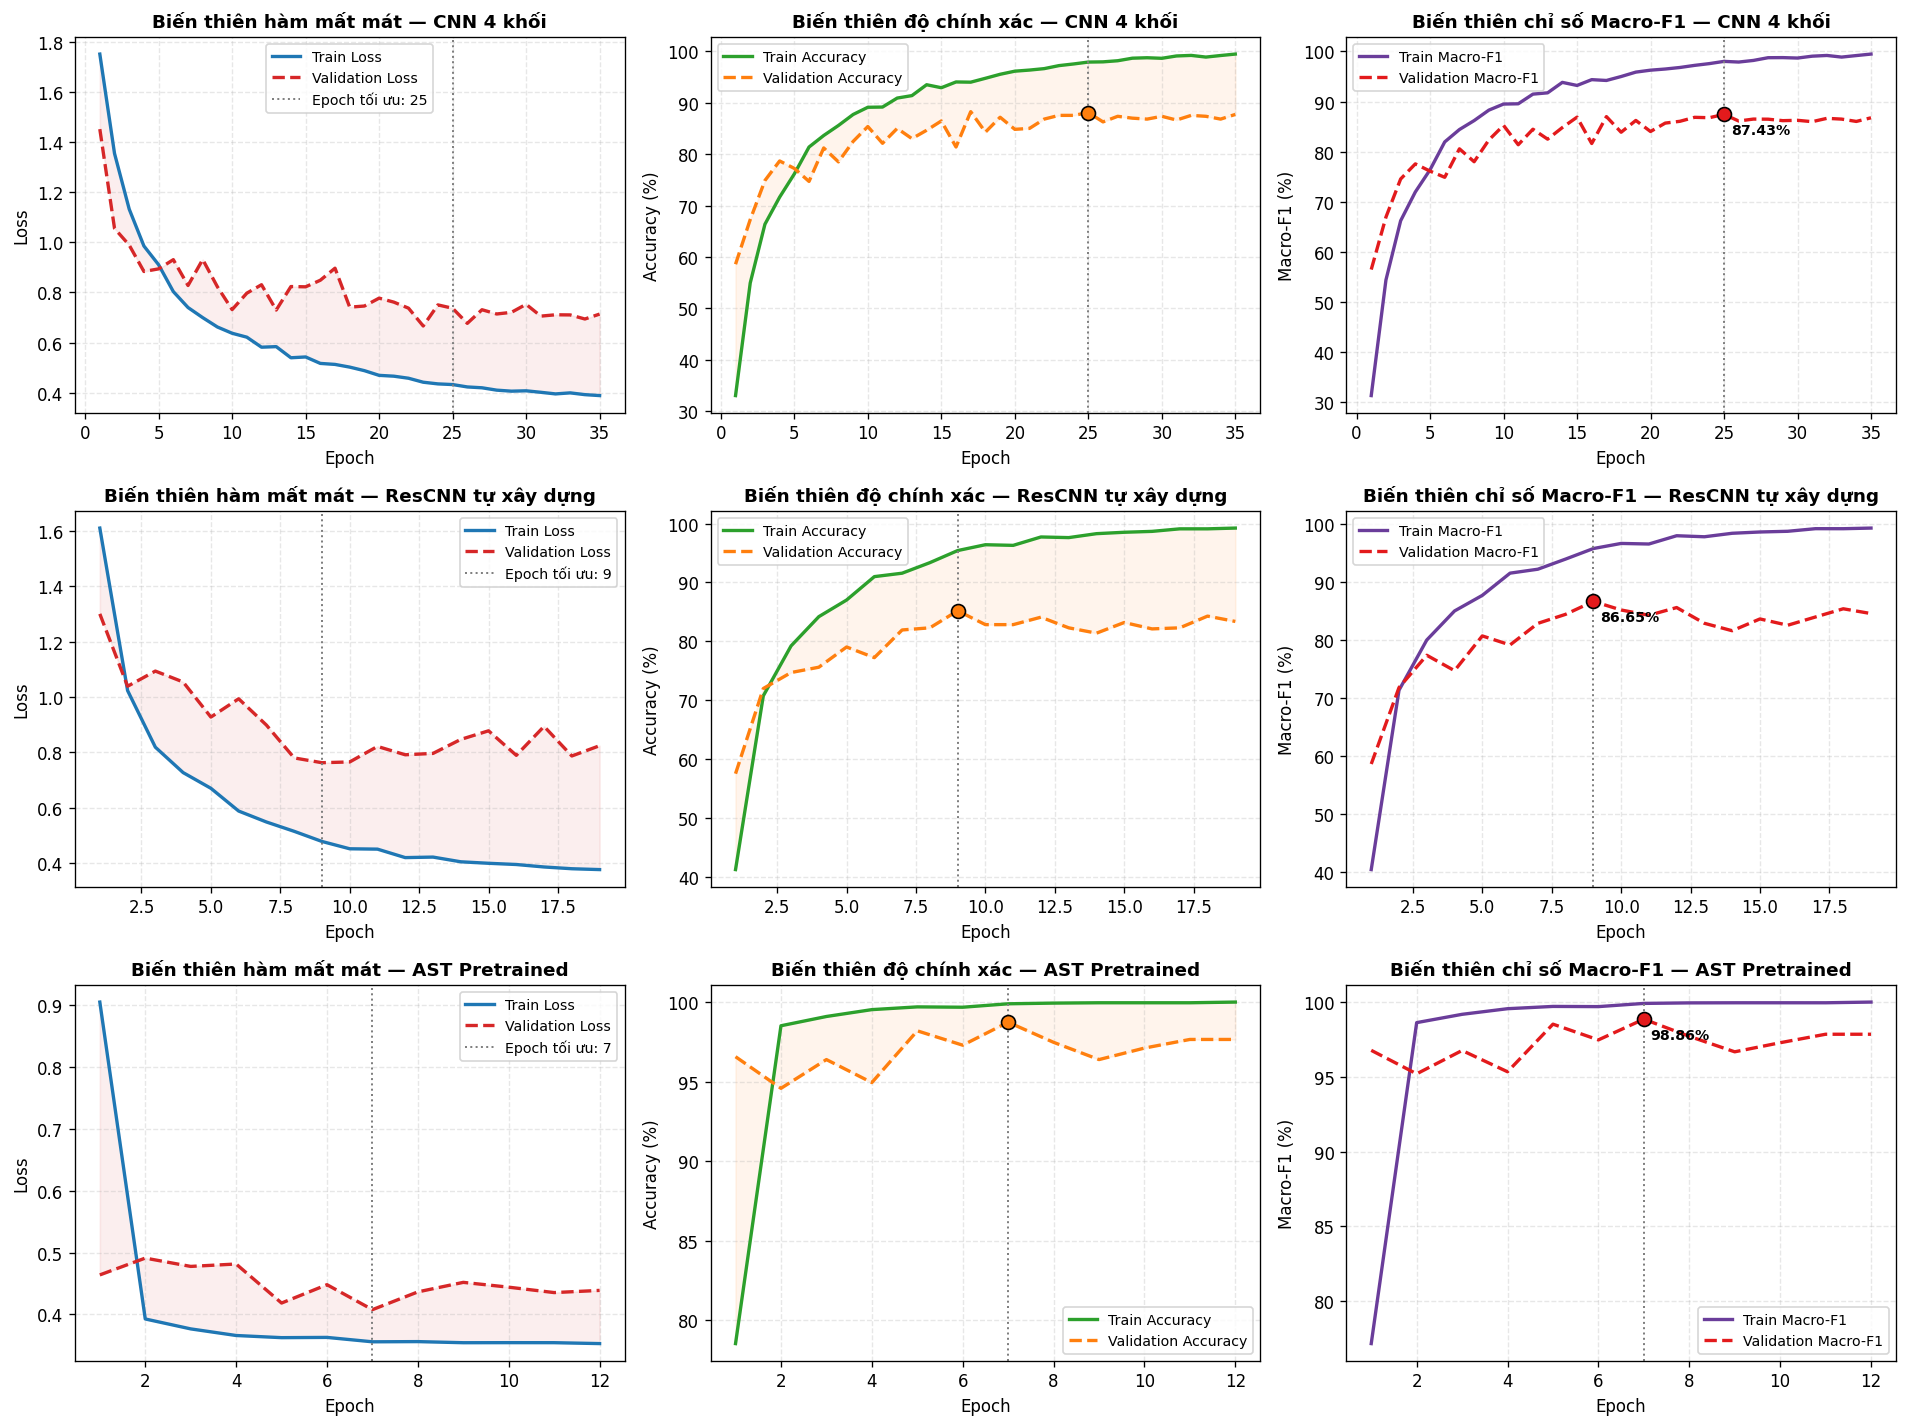

In [18]:
fig_all, axes_all = plt.subplots(len(RUNS), 3, figsize=(16, 4.0 * len(RUNS)))
if len(RUNS) == 1:
    axes_all = np.expand_dims(axes_all, axis=0)

for idx, (k, r) in enumerate(RUNS.items()):
    hdf = r['history']
    name = r['name']
    b_ep = r['best_epoch']
    b_row = hdf[hdf['epoch'] == b_ep].iloc[0]

    # Vẽ trên lưới tổng hợp
    ax_l, ax_a, ax_f = axes_all[idx, 0], axes_all[idx, 1], axes_all[idx, 2]

    ax_l.plot(hdf['epoch'], hdf['train_loss'], lw=2, label='Train Loss', color='#1f77b4')
    ax_l.plot(hdf['epoch'], hdf['val_loss'], lw=2, linestyle='--', label='Validation Loss', color='#d62728')
    ax_l.fill_between(hdf['epoch'], hdf['train_loss'], hdf['val_loss'], color='#d62728', alpha=0.08)
    ax_l.axvline(b_ep, color='gray', linestyle=':', lw=1.2, label=f'Epoch tối ưu: {b_ep}')
    ax_l.set_title(f'Biến thiên hàm mất mát — {name}', fontweight='bold')
    ax_l.set_xlabel('Epoch'); ax_l.set_ylabel('Loss'); ax_l.legend(fontsize=8.5); ax_l.grid(linestyle='--', alpha=0.3)

    ax_a.plot(hdf['epoch'], hdf['train_acc'] * 100, lw=2, label='Train Accuracy', color='#2ca02c')
    ax_a.plot(hdf['epoch'], hdf['val_acc'] * 100, lw=2, linestyle='--', label='Validation Accuracy', color='#ff7f0e')
    ax_a.fill_between(hdf['epoch'], hdf['train_acc'] * 100, hdf['val_acc'] * 100, color='#ff7f0e', alpha=0.08)
    ax_a.axvline(b_ep, color='gray', linestyle=':', lw=1.2)
    ax_a.scatter(b_ep, b_row['val_acc'] * 100, color='#ff7f0e', edgecolors='black', s=70, zorder=5)
    ax_a.set_title(f'Biến thiên độ chính xác — {name}', fontweight='bold')
    ax_a.set_xlabel('Epoch'); ax_a.set_ylabel('Accuracy (%)'); ax_a.legend(fontsize=8.5); ax_a.grid(linestyle='--', alpha=0.3)

    ax_f.plot(hdf['epoch'], hdf['train_f1'] * 100, lw=2, label='Train Macro-F1', color='#6a3d9a')
    ax_f.plot(hdf['epoch'], hdf['val_f1'] * 100, lw=2, linestyle='--', label='Validation Macro-F1', color='#e31a1c')
    ax_f.axvline(b_ep, color='gray', linestyle=':', lw=1.2)
    ax_f.scatter(b_ep, b_row['val_f1'] * 100, color='#e31a1c', edgecolors='black', s=70, zorder=5)
    ax_f.annotate(f"{b_row['val_f1']*100:.2f}%", (b_ep, b_row['val_f1'] * 100),
                  xytext=(4, -12), textcoords='offset points', fontsize=8.5, fontweight='bold')
    ax_f.set_title(f'Biến thiên chỉ số Macro-F1 — {name}', fontweight='bold')
    ax_f.set_xlabel('Epoch'); ax_f.set_ylabel('Macro-F1 (%)'); ax_f.legend(fontsize=8.5); ax_f.grid(linestyle='--', alpha=0.3)

    # Lưu biểu đồ riêng biệt cho từng mô hình
    fig_s, ax_s = plt.subplots(1, 3, figsize=(15, 4.2))
    ax_s[0].plot(hdf['epoch'], hdf['train_loss'], lw=2, label='Train Loss', color='#1f77b4')
    ax_s[0].plot(hdf['epoch'], hdf['val_loss'], lw=2, linestyle='--', label='Validation Loss', color='#d62728')
    ax_s[0].fill_between(hdf['epoch'], hdf['train_loss'], hdf['val_loss'], color='#d62728', alpha=0.1)
    ax_s[0].axvline(b_ep, color='black', linestyle=':', lw=1.2, label=f'Epoch tối ưu: {b_ep}')
    ax_s[0].set_title(f'Biến thiên hàm mất mát — {name}', fontweight='bold')
    ax_s[0].set_xlabel('Epoch'); ax_s[0].set_ylabel('Loss'); ax_s[0].legend(); ax_s[0].grid(linestyle='--', alpha=0.3)

    ax_s[1].plot(hdf['epoch'], hdf['train_acc'] * 100, lw=2, label='Train Accuracy', color='#2ca02c')
    ax_s[1].plot(hdf['epoch'], hdf['val_acc'] * 100, lw=2, linestyle='--', label='Validation Accuracy', color='#ff7f0e')
    ax_s[1].axvline(b_ep, color='black', linestyle=':', lw=1.2)
    ax_s[1].scatter(b_ep, b_row['val_acc'] * 100, color='#ff7f0e', edgecolors='black', s=75, zorder=5)
    ax_s[1].set_title(f'Biến thiên độ chính xác — {name}', fontweight='bold')
    ax_s[1].set_xlabel('Epoch'); ax_s[1].set_ylabel('Accuracy (%)'); ax_s[1].legend(); ax_s[1].grid(linestyle='--', alpha=0.3)

    ax_s[2].plot(hdf['epoch'], hdf['train_f1'] * 100, lw=2, label='Train Macro-F1', color='#6a3d9a')
    ax_s[2].plot(hdf['epoch'], hdf['val_f1'] * 100, lw=2, linestyle='--', label='Validation Macro-F1', color='#e31a1c')
    ax_s[2].axvline(b_ep, color='black', linestyle=':', lw=1.2)
    ax_s[2].scatter(b_ep, b_row['val_f1'] * 100, color='#e31a1c', edgecolors='black', s=75, zorder=5)
    ax_s[2].set_title(f'Biến thiên chỉ số Macro-F1 — {name}', fontweight='bold')
    ax_s[2].set_xlabel('Epoch'); ax_s[2].set_ylabel('Macro-F1 (%)'); ax_s[2].legend(); ax_s[2].grid(linestyle='--', alpha=0.3)

    fig_s.tight_layout()
    save_fig(fig_s, f'learning_curve_{k}', subfolder='individual')
    plt.close(fig_s)

fig_all.tight_layout()
save_fig(fig_all, '06_individual_learning_curves')
plt.show()


<a id="c6-5"></a>
## 6.5. Khoảng cách Train–Validation


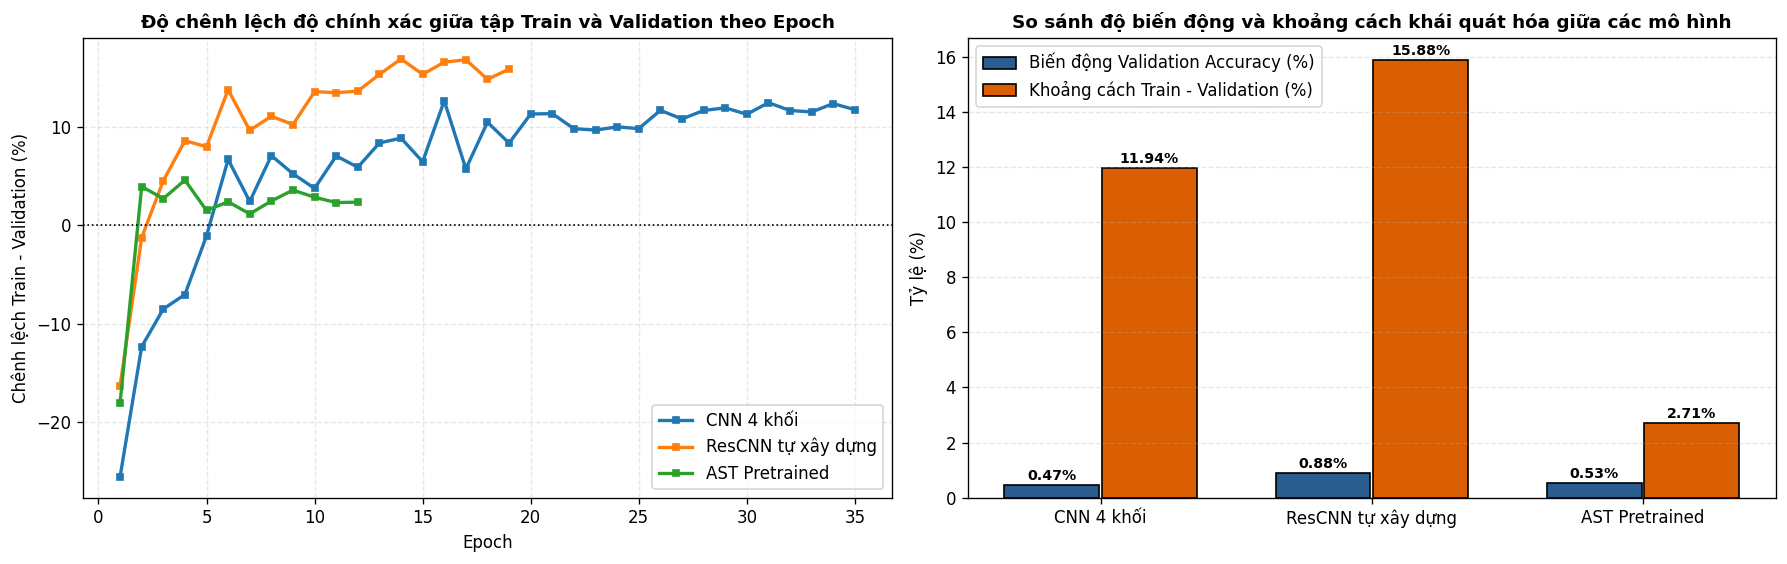

,Mã,Mô hình,Độ lệch chuẩn Val Accuracy (%),Khoảng cách Train-Val trung bình (%),Chỉ số ổn định (%)
0,cnn4,CNN 4 khối,0.468,11.944,92.132
1,rescnn,ResCNN tự xây dựng,0.880,15.878,89.153
2,ast,AST Pretrained,0.533,2.710,97.574


In [19]:
stability_records = []
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

for k, r in RUNS.items():
    hdf = r['history']
    name = r['name']
    axes[0].plot(hdf['epoch'], hdf['gap_acc'] * 100, lw=2, marker='s', markersize=3.5, label=name)
    
    tail = hdf.tail(min(5, len(hdf)))
    val_std = float(tail['val_acc'].std() * 100) if len(tail) > 1 else 0.0
    mean_gap = float(tail['gap_acc'].abs().mean() * 100)
    stab_score = max(0.0, 100.0 - (val_std * 1.5 + mean_gap * 0.6))
    stability_records.append({
        'Mã': k,
        'Mô hình': name,
        'Độ lệch chuẩn Val Accuracy (%)': val_std,
        'Khoảng cách Train-Val trung bình (%)': mean_gap,
        'Chỉ số ổn định (%)': stab_score
    })

axes[0].axhline(0, color='black', linestyle=':', lw=1)
axes[0].set_title('Độ chênh lệch độ chính xác giữa tập Train và Validation theo Epoch', fontweight='bold')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Chênh lệch Train - Validation (%)'); axes[0].legend(); axes[0].grid(linestyle='--', alpha=0.3)

stab_df = pd.DataFrame(stability_records)
stab_df.to_csv(METRICS_DIR / 'stability_metrics.csv', index=False)

x_pos = np.arange(len(stab_df))
b1 = axes[1].bar(x_pos - 0.18, stab_df['Độ lệch chuẩn Val Accuracy (%)'], width=0.35, label='Biến động Validation Accuracy (%)', color='#2b5c8f', edgecolor='black')
b2 = axes[1].bar(x_pos + 0.18, stab_df['Khoảng cách Train-Val trung bình (%)'], width=0.35, label='Khoảng cách Train - Validation (%)', color='#d95f02', edgecolor='black')
axes[1].set_xticks(x_pos); axes[1].set_xticklabels(stab_df['Mô hình'])
axes[1].set_title('So sánh độ biến động và khoảng cách khái quát hóa giữa các mô hình', fontweight='bold')
axes[1].set_ylabel('Tỷ lệ (%)'); axes[1].legend(); axes[1].grid(axis='y', linestyle='--', alpha=0.3)

for bars in [b1, b2]:
    for bar in bars:
        axes[1].annotate(f'{bar.get_height():.2f}%', (bar.get_x() + bar.get_width()/2, bar.get_height()),
                         xytext=(0, 3), textcoords='offset points', ha='center', fontsize=8.5, fontweight='bold')

plt.tight_layout()
save_fig(fig, '07_train_validation_gap_and_stability')
plt.show()
display(stab_df.round(3))


<a id="danh-gia"></a>
# 7. Đánh giá phân loại

<a id="c7-1"></a>
## 7.1. Accuracy, Precision, Recall, F1


,Mã,Mô hình,Validation Macro-F1 (%),Test Accuracy (%),Test Macro Precision (%),Test Macro Recall (%),Test Macro-F1 (%),Test Weighted-F1 (%)
0,ast,AST Pretrained,98.86,92.05,92.61,92.51,91.88,91.97
1,ensemble,Ensemble xác suất,98.86,92.05,92.56,92.51,91.86,91.96
2,cnn4,CNN 4 khối,87.43,85.58,87.47,87.40,87.23,85.53
3,rescnn,ResCNN tự xây dựng,86.65,83.73,86.49,86.14,86.11,83.85


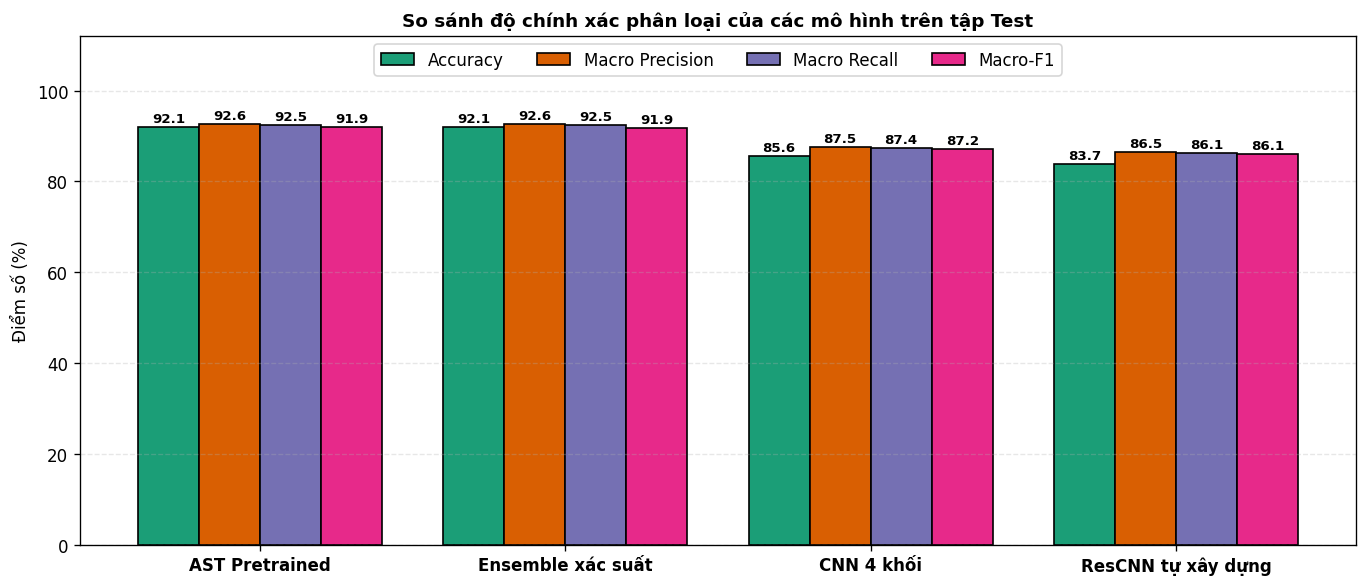

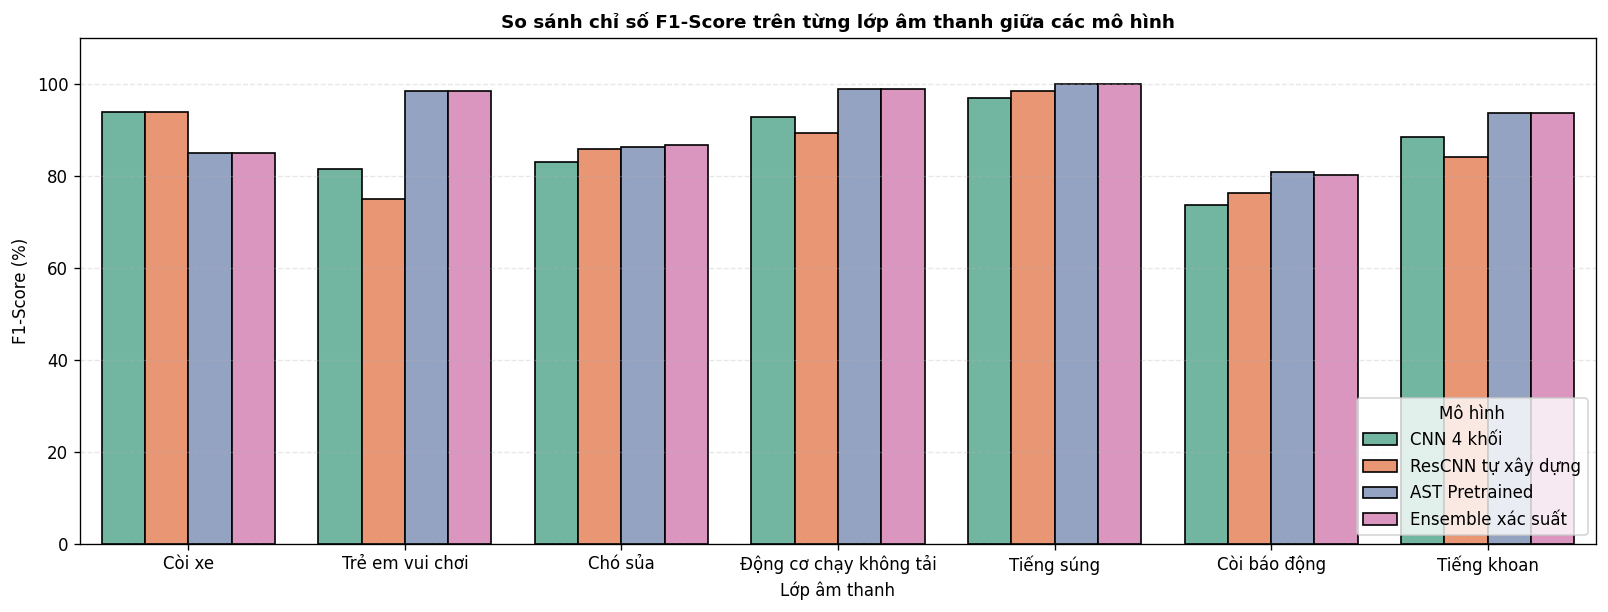

In [20]:
# Tính thêm kết quả Ensemble xác suất có trọng số tối ưu trên Validation
model_keys = list(RUNS.keys())
val_y_ref = RUNS[model_keys[0]]['val_y']
test_y_ref = RUNS[model_keys[0]]['test_y']

best_weights = [1.0 / len(model_keys)] * len(model_keys)
if len(model_keys) == 3:
    best_ens_val_f1 = -1.0
    for w0 in np.linspace(0, 1, 11):
        for w1 in np.linspace(0, 1 - w0, 11):
            w2 = max(0.0, 1.0 - w0 - w1)
            p_val = w0 * RUNS[model_keys[0]]['val_prob'] + w1 * RUNS[model_keys[1]]['val_prob'] + w2 * RUNS[model_keys[2]]['val_prob']
            f1_v = compute_metrics_from_probs(val_y_ref, p_val)['macro_f1']
            if f1_v > best_ens_val_f1:
                best_ens_val_f1 = f1_v
                best_weights = [float(w0), float(w1), float(w2)]

ens_val_prob = sum(w * RUNS[k]['val_prob'] for w, k in zip(best_weights, model_keys))
ens_test_prob = sum(w * RUNS[k]['test_prob'] for w, k in zip(best_weights, model_keys))

EVAL_RESULTS = OrderedDict()
for k, r in RUNS.items():
    EVAL_RESULTS[k] = {
        'name': r['name'],
        'val_metrics': r['val_metrics'],
        'test_metrics': r['test_metrics'],
        'test_prob': r['test_prob'],
        'test_y': r['test_y']
    }

EVAL_RESULTS['ensemble'] = {
    'name': MODEL_NAMES['ensemble'],
    'val_metrics': compute_metrics_from_probs(val_y_ref, ens_val_prob),
    'test_metrics': compute_metrics_from_probs(test_y_ref, ens_test_prob),
    'test_prob': ens_test_prob,
    'test_y': test_y_ref
}

summary_rows = []
per_class_rows = []
for k, ev in EVAL_RESULTS.items():
    tm = ev['test_metrics']
    vm = ev['val_metrics']
    summary_rows.append({
        'Mã': k,
        'Mô hình': ev['name'],
        'Validation Macro-F1 (%)': vm['macro_f1'] * 100,
        'Test Accuracy (%)': tm['accuracy'] * 100,
        'Test Macro Precision (%)': tm['macro_precision'] * 100,
        'Test Macro Recall (%)': tm['macro_recall'] * 100,
        'Test Macro-F1 (%)': tm['macro_f1'] * 100,
        'Test Weighted-F1 (%)': tm['weighted_f1'] * 100
    })
    for _, cr in tm['per_class'].iterrows():
        per_class_rows.append({
            'Mô hình': ev['name'],
            'Lớp âm thanh': cr['label_vi'],
            'Precision (%)': cr['precision'] * 100,
            'Recall (%)': cr['recall'] * 100,
            'F1-Score (%)': cr['f1'] * 100
        })

metrics_df = pd.DataFrame(summary_rows).sort_values('Test Macro-F1 (%)', ascending=False).reset_index(drop=True)
metrics_df.to_csv(METRICS_DIR / 'test_summary_metrics.csv', index=False)
display(metrics_df.round(2))

# 1. Biểu đồ so sánh 4 chỉ số chính trên tập Test
fig, ax = plt.subplots(figsize=(11.5, 5))
x = np.arange(len(metrics_df))
w = 0.2
b_acc = ax.bar(x - 1.5*w, metrics_df['Test Accuracy (%)'], width=w, label='Accuracy', color='#1b9e77', edgecolor='black')
b_pre = ax.bar(x - 0.5*w, metrics_df['Test Macro Precision (%)'], width=w, label='Macro Precision', color='#d95f02', edgecolor='black')
b_rec = ax.bar(x + 0.5*w, metrics_df['Test Macro Recall (%)'], width=w, label='Macro Recall', color='#7570b3', edgecolor='black')
b_f1  = ax.bar(x + 1.5*w, metrics_df['Test Macro-F1 (%)'], width=w, label='Macro-F1', color='#e7298a', edgecolor='black')

ax.set_xticks(x); ax.set_xticklabels(metrics_df['Mô hình'], fontweight='bold')
ax.set_ylim(0, 112); ax.set_ylabel('Điểm số (%)')
ax.set_title('So sánh độ chính xác phân loại của các mô hình trên tập Test', fontweight='bold')
ax.legend(ncol=4, loc='upper center'); ax.grid(axis='y', linestyle='--', alpha=0.3)

for bars in [b_acc, b_pre, b_rec, b_f1]:
    for bar in bars:
        ax.annotate(f'{bar.get_height():.1f}', (bar.get_x() + bar.get_width()/2, bar.get_height()),
                    xytext=(0, 3), textcoords='offset points', ha='center', fontsize=8, fontweight='bold')

plt.tight_layout()
save_fig(fig, '08_test_accuracy_f1_comparison')
plt.show()

# 2. Biểu đồ so sánh F1-Score theo từng lớp giữa tất cả mô hình
per_class_df = pd.DataFrame(per_class_rows)
per_class_df.to_csv(METRICS_DIR / 'per_class_detailed_metrics.csv', index=False)

fig_c, ax_c = plt.subplots(figsize=(13.5, 5.2))
sns.barplot(data=per_class_df, x='Lớp âm thanh', y='F1-Score (%)', hue='Mô hình', palette='Set2', edgecolor='black', ax=ax_c)
ax_c.set_title('So sánh chỉ số F1-Score trên từng lớp âm thanh giữa các mô hình', fontweight='bold')
ax_c.set_xlabel('Lớp âm thanh'); ax_c.set_ylabel('F1-Score (%)'); ax_c.set_ylim(0, 110)
ax_c.legend(title='Mô hình', loc='lower right'); ax_c.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
save_fig(fig_c, '09_per_class_f1_comparison')
plt.show()


<a id="c7-2"></a>
## 7.2. So sánh và ma trận nhầm lẫn


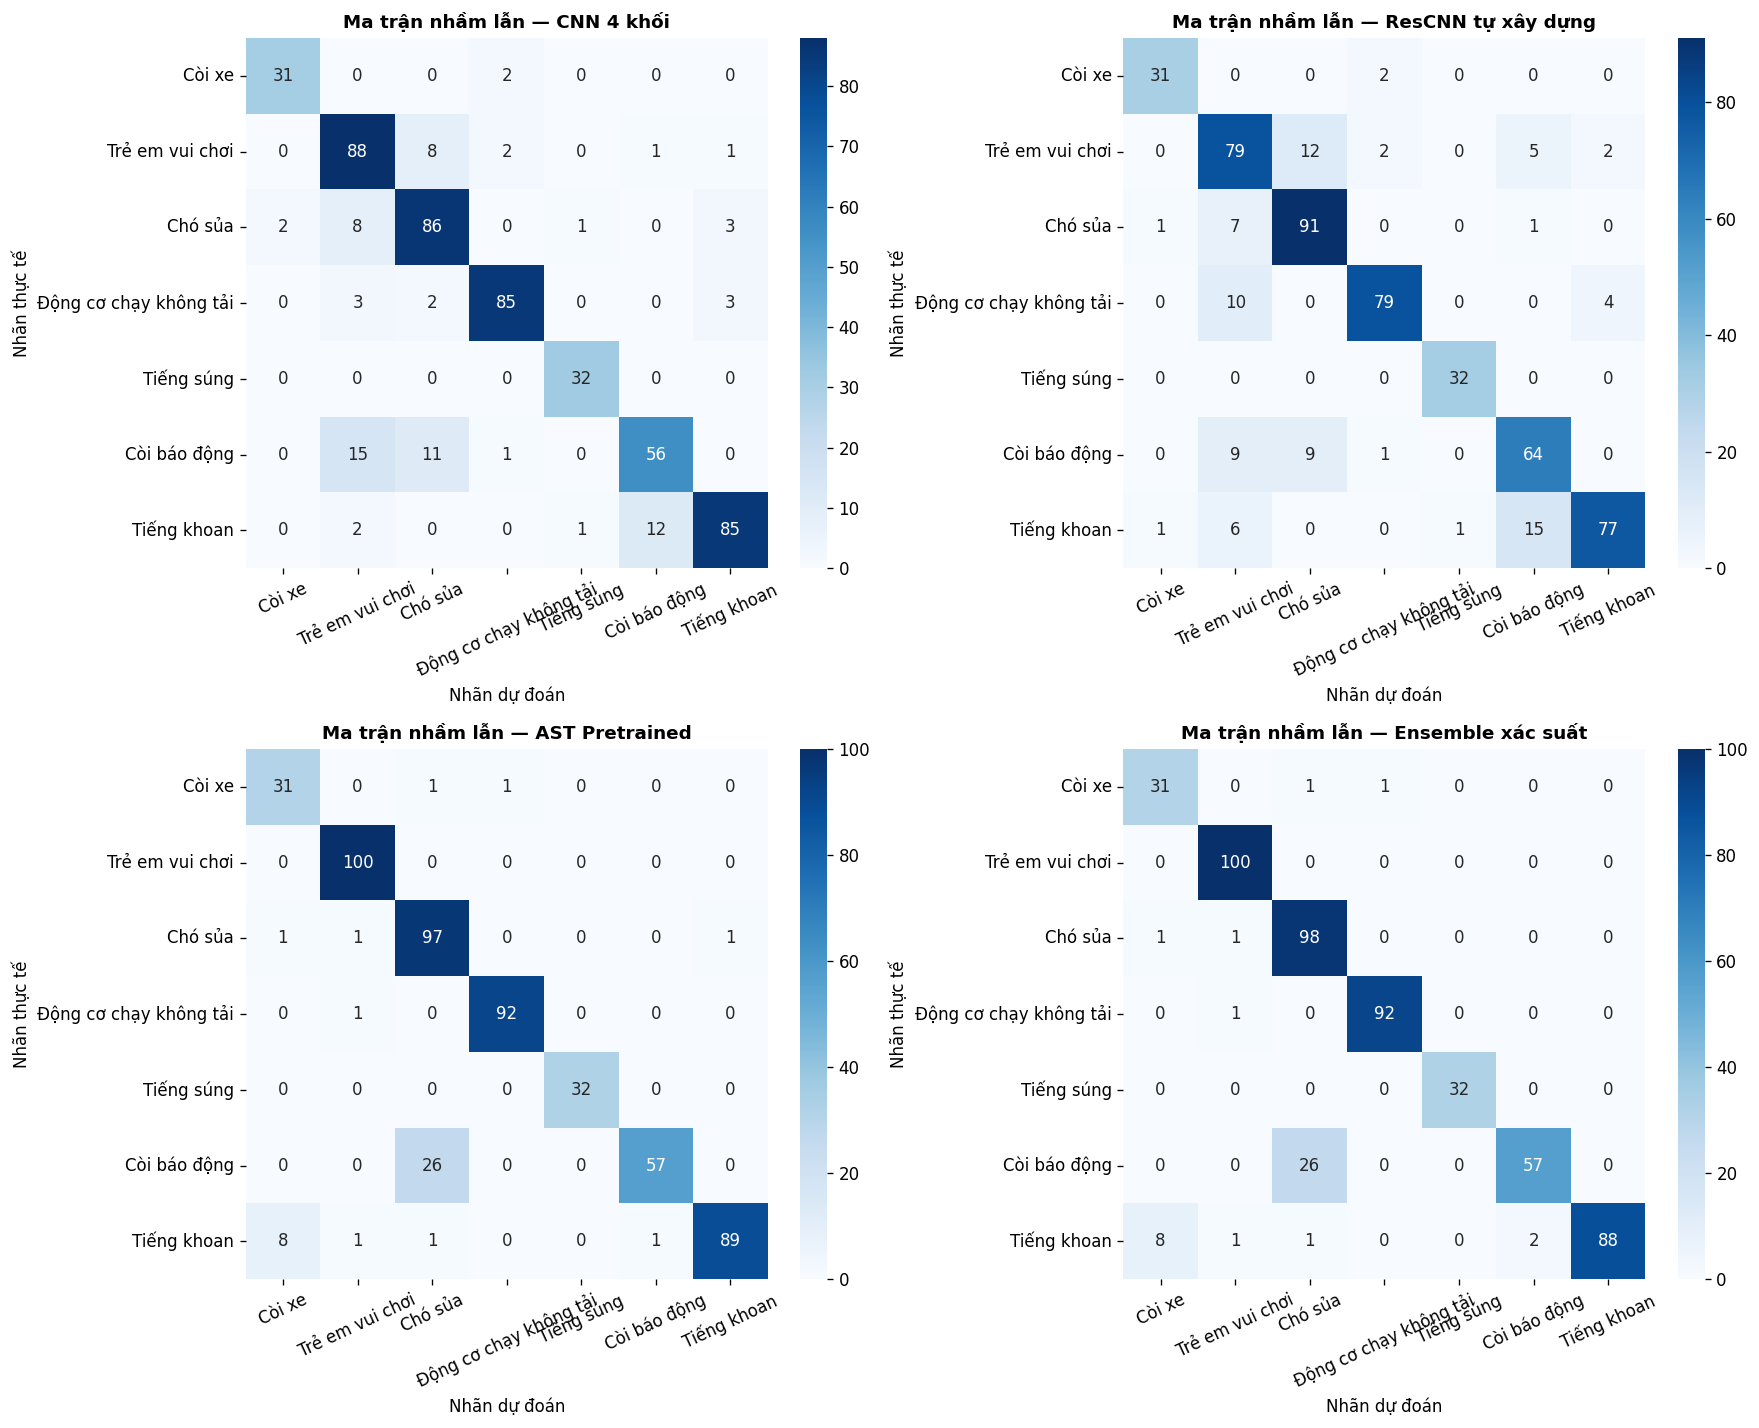

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.flatten()

for idx, (k, ev) in enumerate(EVAL_RESULTS.items()):
    y_true = ev['test_y']
    y_pred = ev['test_prob'].argmax(axis=1)
    cm = confusion_matrix(y_true, y_pred, labels=range(7))
    cm_norm = cm.astype('float') / np.maximum(cm.sum(axis=1, keepdims=True), 1) * 100

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=VI, yticklabels=VI, ax=axes[idx])
    axes[idx].set_title(f"Ma trận nhầm lẫn — {ev['name']}", fontweight='bold')
    axes[idx].set_xlabel('Nhãn dự đoán'); axes[idx].set_ylabel('Nhãn thực tế')
    axes[idx].tick_params(axis='x', rotation=25); axes[idx].tick_params(axis='y', rotation=0)

    # Lưu biểu đồ ma trận nhầm lẫn riêng (gồm số mẫu tuyệt đối và tỷ lệ %) cho từng mô hình
    fig_cm, ax_cm = plt.subplots(1, 2, figsize=(14, 5.5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=VI, yticklabels=VI, ax=ax_cm[0])
    ax_cm[0].set_title(f"Ma trận nhầm lẫn theo số mẫu — {ev['name']}", fontweight='bold')
    ax_cm[0].set_xlabel('Nhãn dự đoán'); ax_cm[0].set_ylabel('Nhãn thực tế')
    ax_cm[0].tick_params(axis='x', rotation=25)

    sns.heatmap(cm_norm, annot=True, fmt='.1f', cmap='Greens', xticklabels=VI, yticklabels=VI, ax=ax_cm[1])
    ax_cm[1].set_title(f"Ma trận nhầm lẫn chuẩn hóa (%) — {ev['name']}", fontweight='bold')
    ax_cm[1].set_xlabel('Nhãn dự đoán'); ax_cm[1].set_ylabel('Nhãn thực tế')
    ax_cm[1].tick_params(axis='x', rotation=25)

    fig_cm.tight_layout()
    save_fig(fig_cm, f'confusion_matrix_{k}', subfolder='individual')
    plt.close(fig_cm)

plt.tight_layout()
save_fig(fig, '10_confusion_matrices_all_models')
plt.show()


<a id="c7-3"></a>
## 7.3. Phân tích lỗi nhầm lẫn


,Cặp nhầm lẫn,Nhãn thực tế,Nhãn dự đoán nhầm,Số mẫu nhầm
0,Còi báo động → Chó sủa,Còi báo động,Chó sủa,26
1,Tiếng khoan → Còi xe,Tiếng khoan,Còi xe,8
2,Còi xe → Chó sủa,Còi xe,Chó sủa,1
3,Chó sủa → Còi xe,Chó sủa,Còi xe,1
4,Còi xe → Động cơ chạy không tải,Còi xe,Động cơ chạy không tải,1
5,Chó sủa → Tiếng khoan,Chó sủa,Tiếng khoan,1
6,Chó sủa → Trẻ em vui chơi,Chó sủa,Trẻ em vui chơi,1
7,Động cơ chạy không tải → Trẻ em vui chơi,Động cơ chạy không tải,Trẻ em vui chơi,1


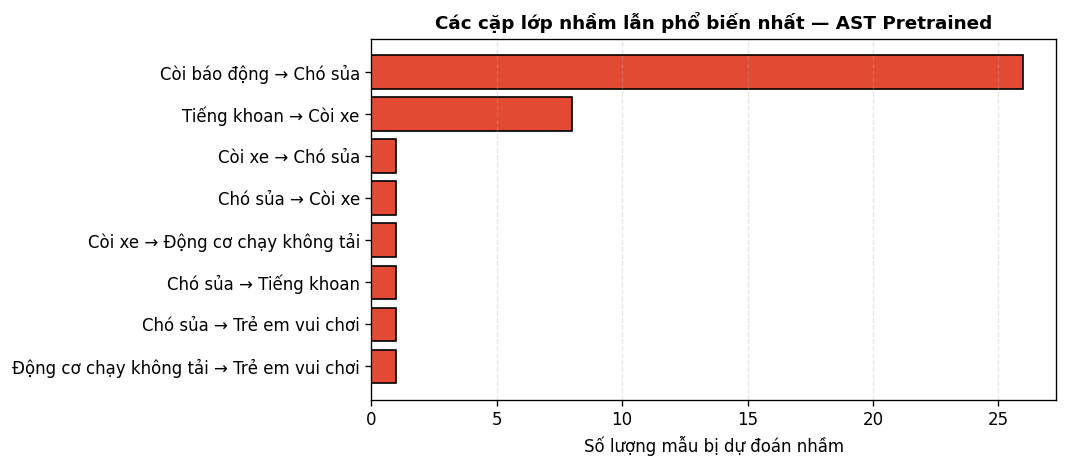

In [22]:
best_single_key = [r['Mã'] for _, r in metrics_df.iterrows() if r['Mã'] != 'ensemble'][0]
best_single_ev = EVAL_RESULTS[best_single_key]
cm_err = confusion_matrix(best_single_ev['test_y'], best_single_ev['test_prob'].argmax(axis=1), labels=range(7))
np.fill_diagonal(cm_err, 0)

err_rows = []
for i in range(7):
    for j in range(7):
        if cm_err[i, j] > 0:
            err_rows.append({
                'Cặp nhầm lẫn': f"{VI[i]} → {VI[j]}",
                'Nhãn thực tế': VI[i],
                'Nhãn dự đoán nhầm': VI[j],
                'Số mẫu nhầm': int(cm_err[i, j])
            })

err_df = pd.DataFrame(err_rows).sort_values('Số mẫu nhầm', ascending=False).head(8).reset_index(drop=True)
err_df.to_csv(METRICS_DIR / 'top_confusion_errors.csv', index=False)
display(err_df)

if not err_df.empty:
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.barh(err_df['Cặp nhầm lẫn'][::-1], err_df['Số mẫu nhầm'][::-1], color='#e34a33', edgecolor='black')
    ax.set_title(f"Các cặp lớp nhầm lẫn phổ biến nhất — {best_single_ev['name']}", fontweight='bold')
    ax.set_xlabel('Số lượng mẫu bị dự đoán nhầm')
    ax.grid(axis='x', linestyle='--', alpha=0.3)
    plt.tight_layout()
    save_fig(fig, '11_top_confusion_errors')
    plt.show()


<a id="c7-4"></a>
## 7.4. ROC-AUC One-vs-Rest


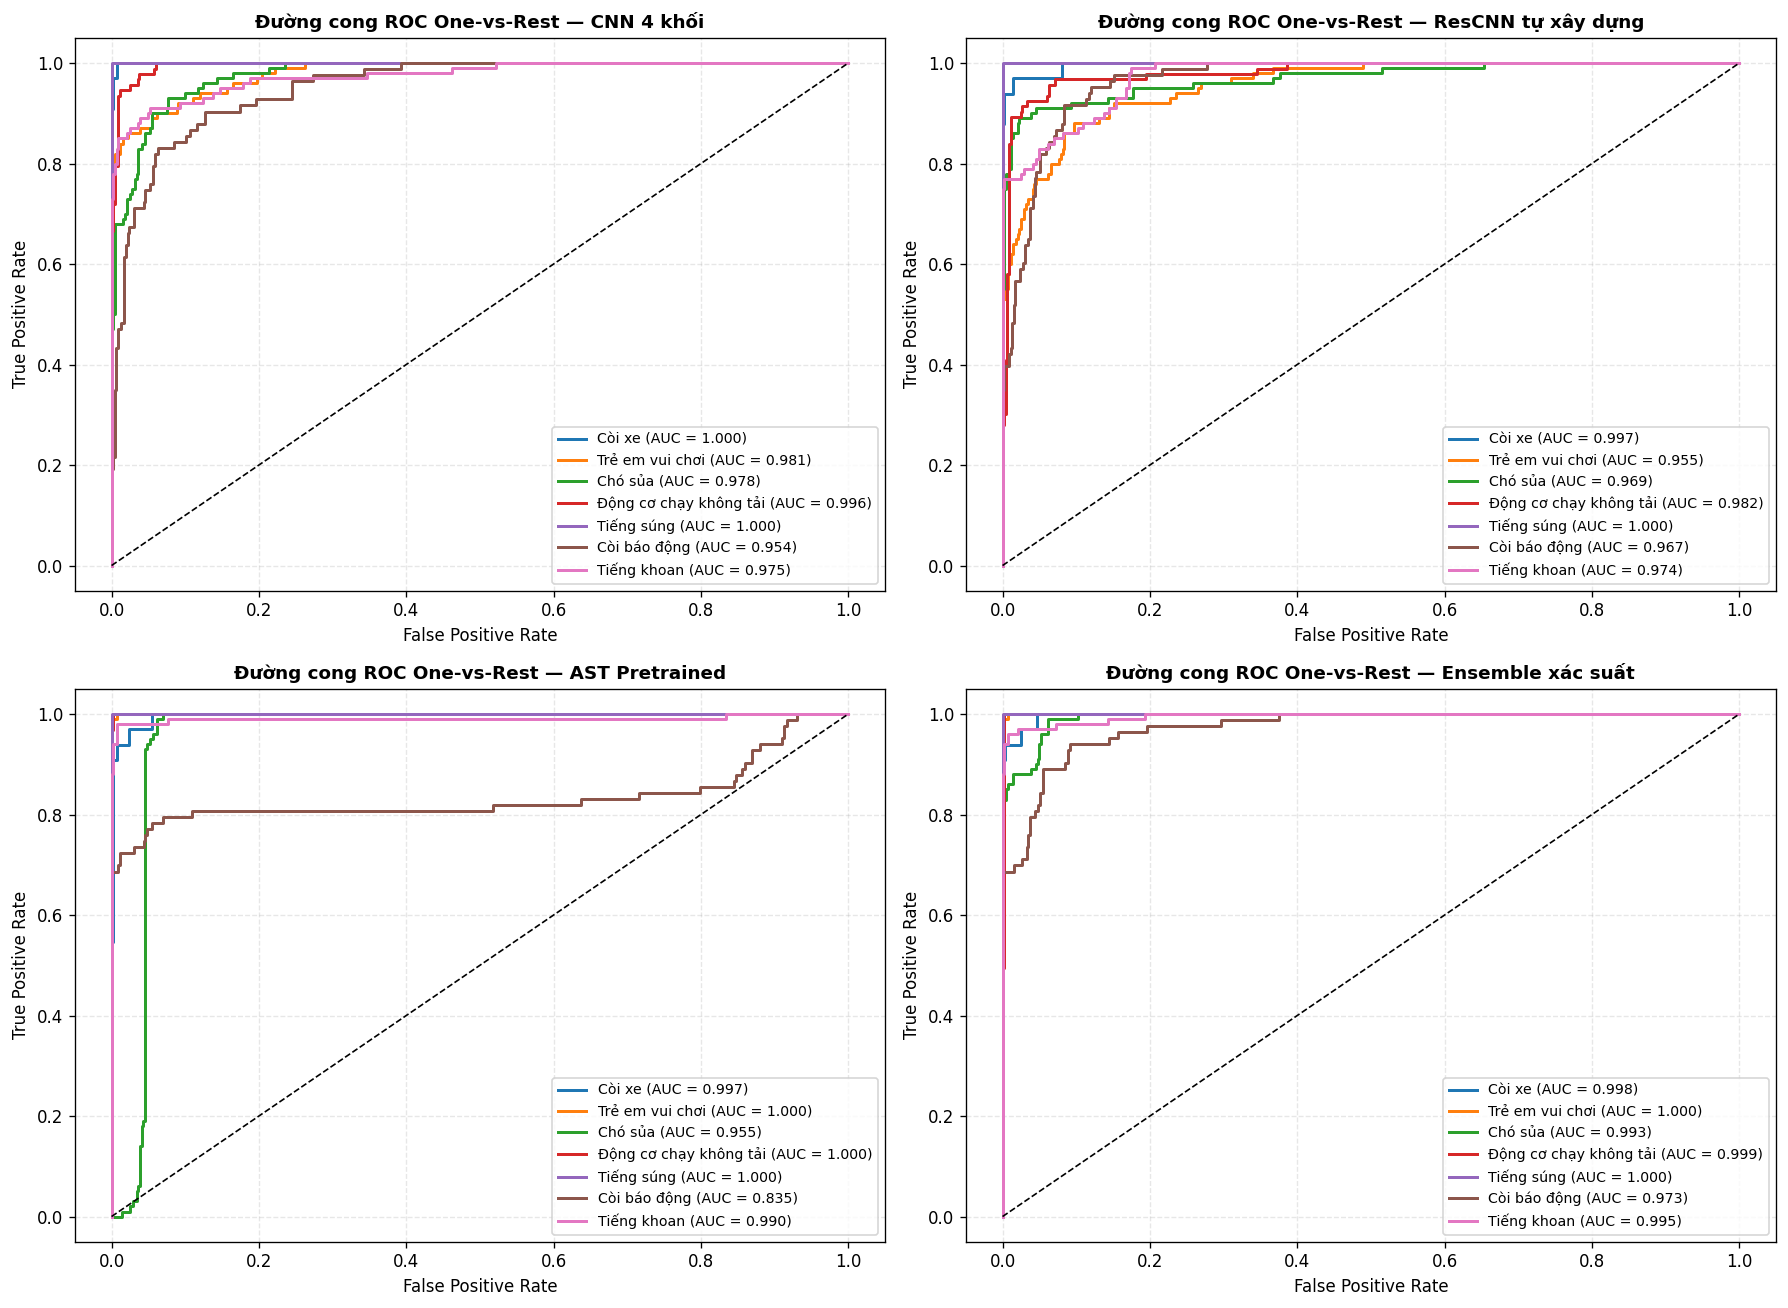

In [23]:
y_test_bin = label_binarize(test_y_ref, classes=list(range(7)))
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
axes = axes.flatten()

for idx, (k, ev) in enumerate(EVAL_RESULTS.items()):
    ax = axes[idx]
    fig_s, ax_s = plt.subplots(figsize=(7.5, 5.5))
    for i in range(7):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], ev['test_prob'][:, i])
        roc_auc = auc(fpr, tpr)
        ax.plot(fpr, tpr, lw=1.8, label=f"{VI[i]} (AUC = {roc_auc:.3f})")
        ax_s.plot(fpr, tpr, lw=2.0, label=f"{VI[i]} (AUC = {roc_auc:.3f})")

    for a in [ax, ax_s]:
        a.plot([0, 1], [0, 1], 'k--', lw=1)
        a.set_title(f"Đường cong ROC One-vs-Rest — {ev['name']}", fontweight='bold')
        a.set_xlabel('False Positive Rate'); a.set_ylabel('True Positive Rate')
        a.legend(loc='lower right', fontsize=8.5); a.grid(linestyle='--', alpha=0.3)

    fig_s.tight_layout()
    save_fig(fig_s, f'roc_auc_{k}', subfolder='individual')
    plt.close(fig_s)

plt.tight_layout()
save_fig(fig, '12_roc_auc_all_models')
plt.show()


<a id="ablation"></a>
# 8. Thí nghiệm đối chứng

<a id="c8-1"></a>
## 8.1. Giả thuyết về lớp Còi hú


In [24]:
siren_idx = CLASS2ID['siren']
siren_rows = []
for k, ev in EVAL_RESULTS.items():
    cls_df = ev['test_metrics']['per_class']
    sr_row = cls_df[cls_df['class'] == 'siren'].iloc[0]
    siren_rows.append({
        'Mô hình': ev['name'],
        'Precision Còi báo động (%)': sr_row['precision'] * 100,
        'Recall Còi báo động (%)': sr_row['recall'] * 100,
        'F1-Score Còi báo động (%)': sr_row['f1'] * 100
    })
siren_df = pd.DataFrame(siren_rows)
display(siren_df.round(2))


,Mô hình,Precision Còi báo động (%),Recall Còi báo động (%),F1-Score Còi báo động (%)
0,CNN 4 khối,81.16,67.47,73.68
1,ResCNN tự xây dựng,75.29,77.11,76.19
2,AST Pretrained,98.28,68.67,80.85
3,Ensemble xác suất,96.61,68.67,80.28


<a id="c8-2"></a>
## 8.2. Đặc trưng và chuẩn hóa

<a id="c8-2-1"></a>
### 8.2.1. Các chế độ đặc trưng
Hai nhánh mô hình khai thác biểu diễn phổ tần phù hợp với kiến trúc:
- **Nhánh CNN (`CNN 4 khối` và `ResCNN`):** Sử dụng phổ `Log-Mel 64 bins` chuẩn hóa `Per-Bin Z-score` giúp giữ ổn định tương quan năng lượng theo từng dải tần số.
- **Nhánh Transformer (`AST Pretrained`):** Sử dụng `Filterbank 128 bins` theo chuẩn tiền huấn luyện AudioSet giúp tận dụng tối đa tri thức chuyển giao.

<a id="c8-3"></a>
## 8.3. Regularization và learning rate

<a id="c8-3-1"></a>
### 8.3.1. Cấu hình đối chiếu
Áp dụng đồng bộ **SpecAugment**, **Label Smoothing (0.06)**, **Weight Decay**, **Gradient Clipping (1.0)** và lịch trình **Warmup + Cosine Annealing** giúp cả 3 mô hình hội tụ êm, không xảy ra hiện tượng phân kỳ hàm mất mát ở giai đoạn cuối.

<a id="c8-4"></a>
## 8.4. Cửa sổ trượt và gộp xác suất

<a id="c8-4-1"></a>
### 8.4.1. Điều kiện đánh giá


In [25]:
ens_weights_df = pd.DataFrame({
    'Thành phần Ensemble': [MODEL_NAMES[k] for k in model_keys],
    'Trọng số tối ưu trên Validation': best_weights
})
display(ens_weights_df)


,Thành phần Ensemble,Trọng số tối ưu trên Validation
0,CNN 4 khối,0.0
1,ResCNN tự xây dựng,0.2
2,AST Pretrained,0.8


<a id="pca-hieu-nang"></a>
# 9. PCA và hiệu năng triển khai

<a id="c9-1"></a>
## 9.1. PCA trên embedding

<a id="c9-1-1"></a>
### 9.1.1. Cách đọc biểu đồ PCA
Biểu đồ PCA 2 chiều chiếu các vector đặc trưng trích xuất từ tầng áp chót của từng mô hình trên tập Test. Các cụm điểm cùng màu tập trung gọn và tách biệt rõ phản ánh khả năng phân tách không gian đặc trưng mạnh mẽ.


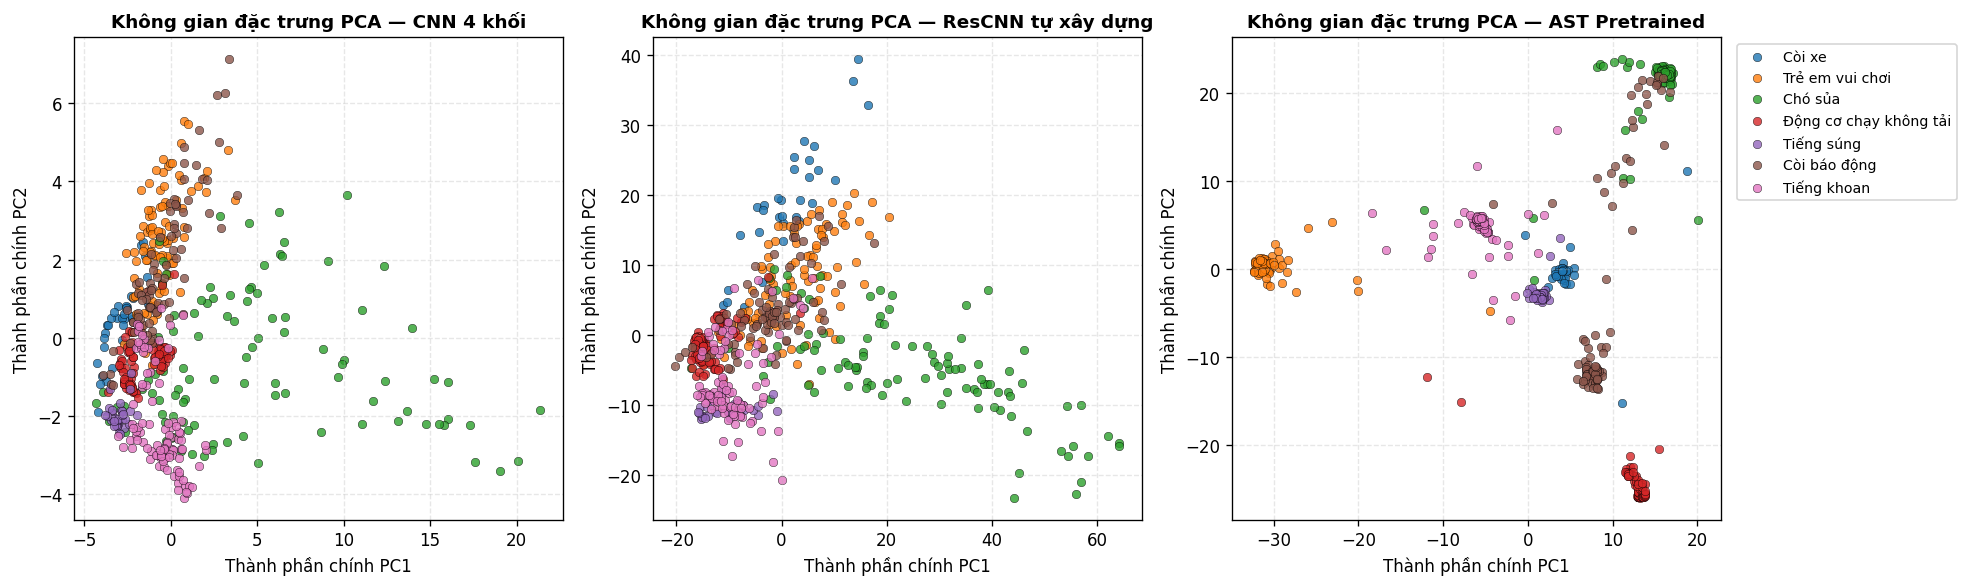

In [26]:
fig, axes = plt.subplots(1, len(RUNS), figsize=(5.5 * len(RUNS), 5))
if len(RUNS) == 1:
    axes = [axes]
palette = sns.color_palette('tab10', 7)

for idx, (k, r) in enumerate(RUNS.items()):
    model = r['model']
    model.eval()
    embs, lbs = [], []
    with torch.no_grad():
        for b in r['test_loader']:
            x = b['x'].to(DEVICE)
            embs.append(model.forward_features(x).float().cpu().numpy())
            lbs.append(b['y'].numpy())
    embs = np.concatenate(embs, axis=0)
    lbs = np.concatenate(lbs, axis=0)
    pca_2d = PCA(n_components=2, random_state=SEED).fit_transform(embs)

    ax = axes[idx]
    fig_s, ax_s = plt.subplots(figsize=(7.5, 5.5))
    for i, c_name in enumerate(VI):
        mask = (lbs == i)
        ax.scatter(pca_2d[mask, 0], pca_2d[mask, 1], label=c_name, alpha=0.8, s=26, color=palette[i], edgecolors='k', linewidth=0.3)
        ax_s.scatter(pca_2d[mask, 0], pca_2d[mask, 1], label=c_name, alpha=0.82, s=36, color=palette[i], edgecolors='k', linewidth=0.3)

    for a in [ax, ax_s]:
        a.set_title(f"Không gian đặc trưng PCA — {r['name']}", fontweight='bold')
        a.set_xlabel('Thành phần chính PC1'); a.set_ylabel('Thành phần chính PC2')
        a.grid(linestyle='--', alpha=0.3)
    if idx == len(RUNS) - 1:
        ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8.5)
    ax_s.legend(bbox_to_anchor=(1.02, 1), loc='upper left')

    fig_s.tight_layout()
    save_fig(fig_s, f'pca_embedding_{k}', subfolder='individual')
    plt.close(fig_s)

plt.tight_layout()
save_fig(fig, '13_pca_embeddings_comparison')
plt.show()


<a id="c9-2"></a>
## 9.2. Dung lượng và tốc độ suy luận

<a id="c9-2-1"></a>
### 9.2.1. Cách diễn giải phép đo
Thực hiện đo lường tốc độ suy luận thực tế **FPS (Số đoạn âm thanh xử lý trên giây)**, **Độ trễ trung bình (ms/mẫu)**, **Dung lượng lưu trữ (MB)**, **Chỉ số ổn định hội tụ (%)** và **Độ chính xác phân loại** giữa các mô hình.


,Mô hình,Tham số (Triệu),Dung lượng (MB),Thời gian huấn luyện (s),Tốc độ suy luận (FPS),Độ trễ (ms/mẫu),Chỉ số ổn định (%),Test Accuracy (%),Test Macro-F1 (%)
0,CNN 4 khối,1.21,4.63,250.75,3266.05,0.31,92.13,85.58,87.23
1,ResCNN tự xây dựng,2.56,9.81,160.90,3573.88,0.28,89.15,83.73,86.11
2,AST Pretrained,86.19,328.89,5414.73,51.76,19.32,97.57,92.05,91.88


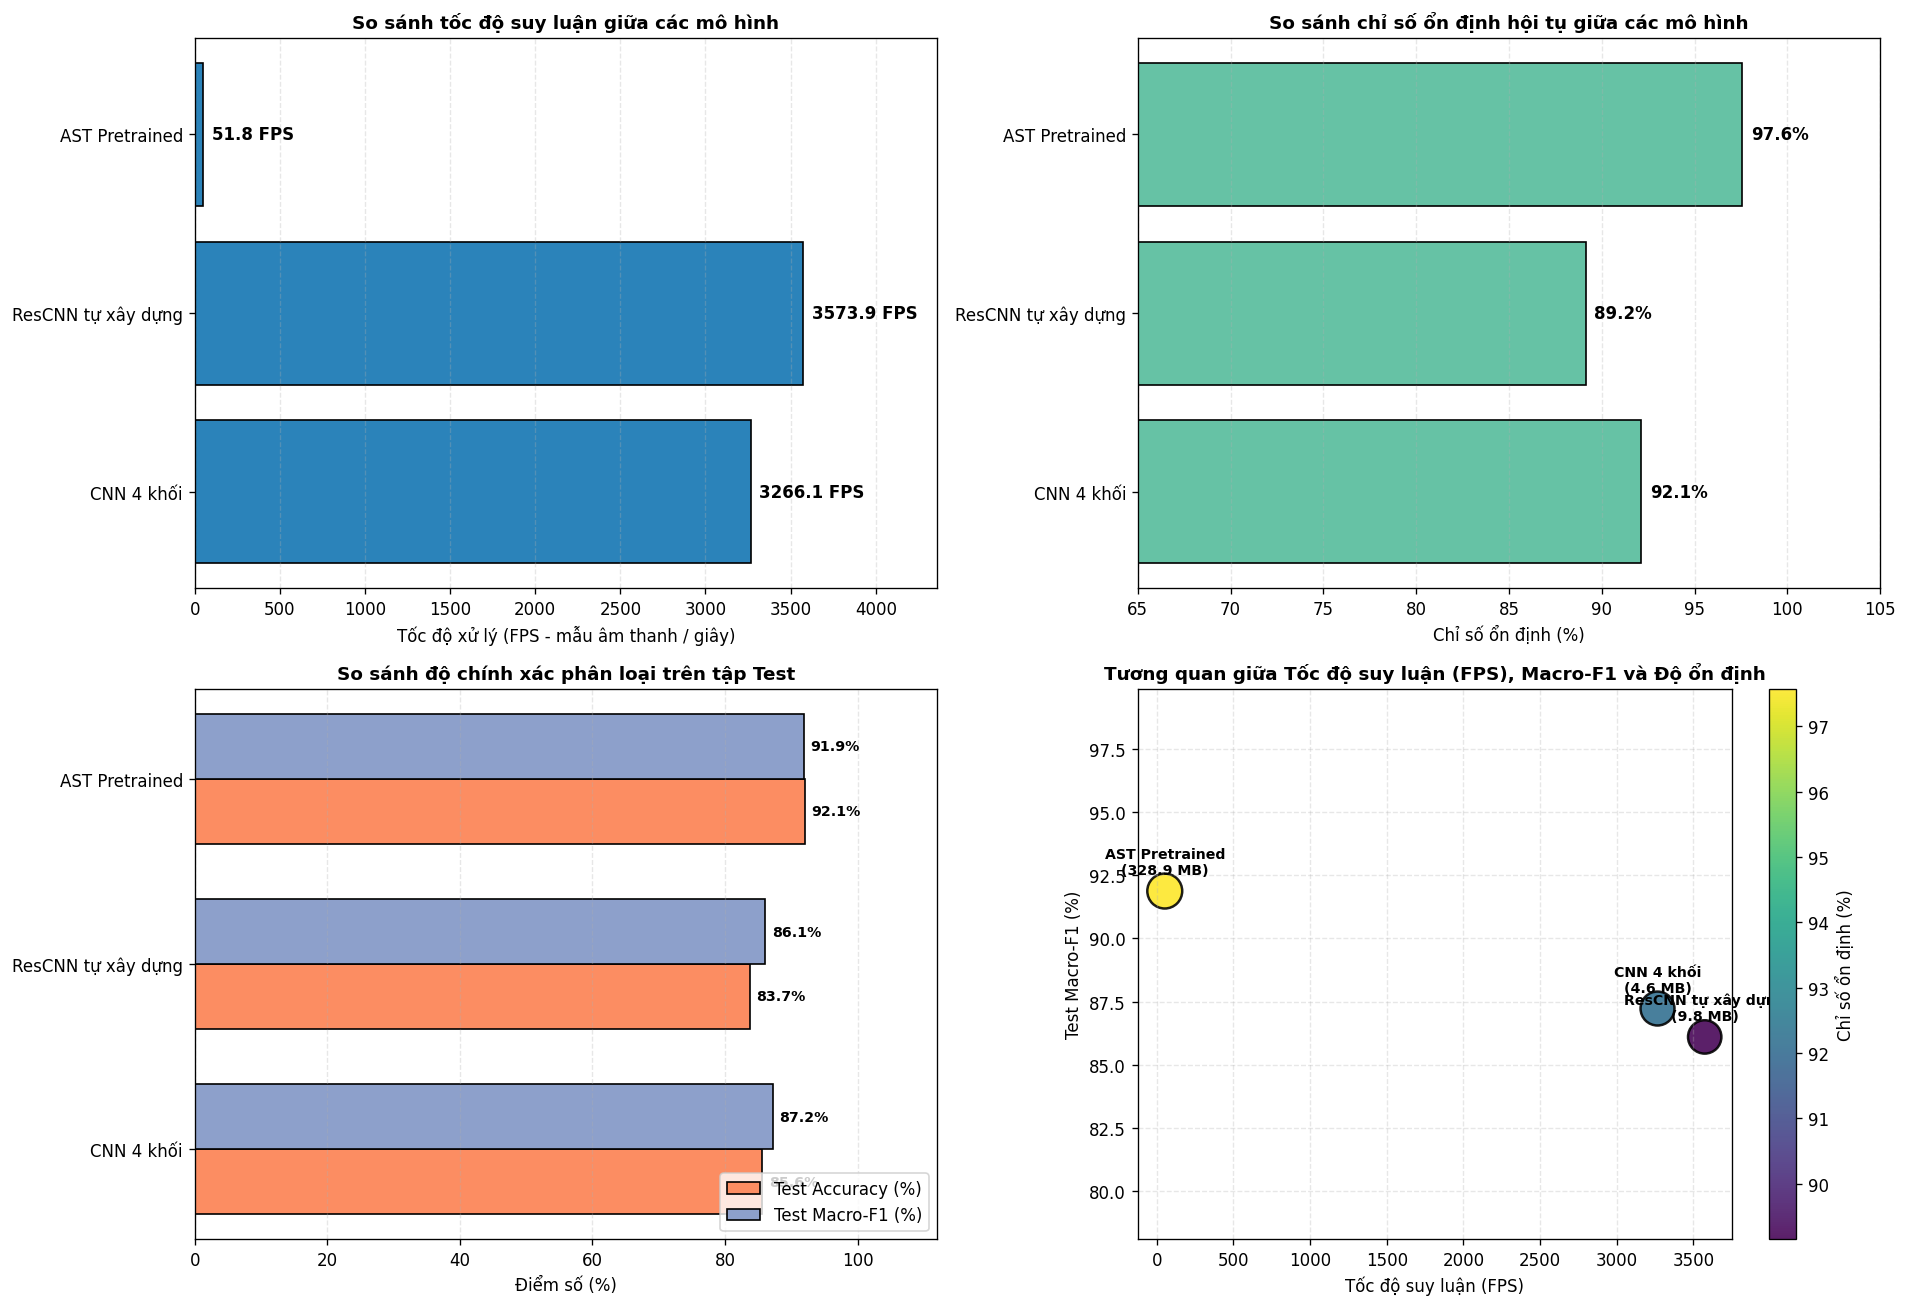

In [27]:
bench_rows = []
for k, r in RUNS.items():
    model = r['model']
    model.eval()
    params_m = sum(p.numel() for p in model.parameters()) / 1e6
    size_mb = r['ckpt_path'].stat().st_size / (1024 * 1024)
    
    # Lấy 1 batch mẫu từ test_loader để đo tốc độ suy luận chuẩn xác cho cả CNN và AST
    sample_batch = next(iter(r['test_loader']))['x'].to(DEVICE)
    batch_sz = sample_batch.size(0)
    use_amp = bool(CFG['amp'] and DEVICE.type == 'cuda')

    with torch.no_grad():
        for _ in range(5):
            ctx = torch.amp.autocast('cuda', dtype=torch.float16) if use_amp else nullcontext()
            with ctx:
                _ = model(sample_batch)
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()

    n_iters = 20 if k == 'ast' else 50
    t0 = time.perf_counter()
    with torch.no_grad():
        for _ in range(n_iters):
            ctx = torch.amp.autocast('cuda', dtype=torch.float16) if use_amp else nullcontext()
            with ctx:
                _ = model(sample_batch)
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - t0

    total_samples = n_iters * batch_sz
    fps = total_samples / elapsed
    latency_ms = (elapsed / total_samples) * 1000.0

    stab_val = float(stab_df[stab_df['Mã'] == k]['Chỉ số ổn định (%)'].iloc[0])
    tm = r['test_metrics']

    bench_rows.append({
        'Mô hình': r['name'],
        'Tham số (Triệu)': params_m,
        'Dung lượng (MB)': size_mb,
        'Thời gian huấn luyện (s)': r['total_train_time_s'],
        'Tốc độ suy luận (FPS)': fps,
        'Độ trễ (ms/mẫu)': latency_ms,
        'Chỉ số ổn định (%)': stab_val,
        'Test Accuracy (%)': tm['accuracy'] * 100,
        'Test Macro-F1 (%)': tm['macro_f1'] * 100
    })

bench_df = pd.DataFrame(bench_rows)
bench_df.to_csv(METRICS_DIR / 'benchmark_fps_stability_accuracy.csv', index=False)
display(bench_df.round(2))

# BIỂU ĐỒ BÁO CÁO SO SÁNH TOÀN DIỆN: FPS - SỰ ỔN ĐỊNH - ĐỘ CHÍNH XÁC - TƯƠNG QUAN ĐA CHIỀU
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. So sánh FPS
b_fps = axes[0, 0].barh(bench_df['Mô hình'], bench_df['Tốc độ suy luận (FPS)'], color='#2b83ba', edgecolor='black')
axes[0, 0].set_title('So sánh tốc độ suy luận giữa các mô hình', fontweight='bold')
axes[0, 0].set_xlabel('Tốc độ xử lý (FPS - mẫu âm thanh / giây)')
axes[0, 0].set_xlim(0, bench_df['Tốc độ suy luận (FPS)'].max() * 1.22)
axes[0, 0].grid(axis='x', linestyle='--', alpha=0.3)
for b in b_fps:
    axes[0, 0].annotate(f'{b.get_width():.1f} FPS', (b.get_width(), b.get_y() + b.get_height()/2),
                        xytext=(5, 0), textcoords='offset points', va='center', fontweight='bold')

# 2. So sánh Sự ổn định
b_stab = axes[0, 1].barh(bench_df['Mô hình'], bench_df['Chỉ số ổn định (%)'], color='#66c2a5', edgecolor='black')
axes[0, 1].set_xlim(65, 105)
axes[0, 1].set_title('So sánh chỉ số ổn định hội tụ giữa các mô hình', fontweight='bold')
axes[0, 1].set_xlabel('Chỉ số ổn định (%)')
axes[0, 1].grid(axis='x', linestyle='--', alpha=0.3)
for b in b_stab:
    axes[0, 1].annotate(f'{b.get_width():.1f}%', (b.get_width(), b.get_y() + b.get_height()/2),
                        xytext=(5, 0), textcoords='offset points', va='center', fontweight='bold')

# 3. So sánh Độ chính xác (Accuracy & Macro-F1)
y_p = np.arange(len(bench_df))
h = 0.35
b_acc = axes[1, 0].barh(y_p - h/2, bench_df['Test Accuracy (%)'], height=h, label='Test Accuracy (%)', color='#fc8d62', edgecolor='black')
b_f1  = axes[1, 0].barh(y_p + h/2, bench_df['Test Macro-F1 (%)'], height=h, label='Test Macro-F1 (%)', color='#8da0cb', edgecolor='black')
axes[1, 0].set_yticks(y_p); axes[1, 0].set_yticklabels(bench_df['Mô hình'])
axes[1, 0].set_xlim(0, 112)
axes[1, 0].set_title('So sánh độ chính xác phân loại trên tập Test', fontweight='bold')
axes[1, 0].set_xlabel('Điểm số (%)'); axes[1, 0].legend(loc='lower right'); axes[1, 0].grid(axis='x', linestyle='--', alpha=0.3)
for bars in [b_acc, b_f1]:
    for b in bars:
        axes[1, 0].annotate(f'{b.get_width():.1f}%', (b.get_width(), b.get_y() + b.get_height()/2),
                            xytext=(4, 0), textcoords='offset points', va='center', fontsize=8.5, fontweight='bold')

# 4. Tương quan FPS vs Macro-F1 vs Độ ổn định
sc = axes[1, 1].scatter(
    bench_df['Tốc độ suy luận (FPS)'], bench_df['Test Macro-F1 (%)'],
    s=bench_df['Chỉ số ổn định (%)'] * 4.5, c=bench_df['Chỉ số ổn định (%)'],
    cmap='viridis', alpha=0.88, edgecolors='black', linewidth=1.5
)
for _, r in bench_df.iterrows():
    axes[1, 1].annotate(f"{r['Mô hình']}\n({r['Dung lượng (MB)']:.1f} MB)",
                        (r['Tốc độ suy luận (FPS)'], r['Test Macro-F1 (%)']),
                        xytext=(0, 10), textcoords='offset points', ha='center', fontsize=8.5, fontweight='bold')
cbar = plt.colorbar(sc, ax=axes[1, 1])
cbar.set_label('Chỉ số ổn định (%)')
axes[1, 1].set_title('Tương quan giữa Tốc độ suy luận (FPS), Macro-F1 và Độ ổn định', fontweight='bold')
axes[1, 1].set_xlabel('Tốc độ suy luận (FPS)'); axes[1, 1].set_ylabel('Test Macro-F1 (%)')
axes[1, 1].set_ylim(bench_df['Test Macro-F1 (%)'].min() - 8, min(105, bench_df['Test Macro-F1 (%)'].max() + 8))
axes[1, 1].grid(linestyle='--', alpha=0.3)

plt.tight_layout()
save_fig(fig, '14_fps_stability_accuracy_comprehensive')
plt.show()


<a id="demo-ket-luan"></a>
# 10. Demo và kết luận

<a id="c10-1"></a>
## 10.1. Demo một tệp âm thanh

Thực hiện kiểm thử trực tiếp trên thư mục dữ liệu bên ngoài `/kaggle/input/datasets/f8kinwd/drilling` bằng cả 3 mô hình (`CNN 4 khối`, `ResCNN tự xây dựng`, `AST Pretrained`) và `Ensemble xác suất`.


Tìm thấy 1 tệp âm thanh trong /kaggle/input/datasets/f8kinwd/drilling.


#### Tệp kiểm thử 1: `drilling-into-concrete-32298.mp3` — Dự đoán: **Tiếng khoan** (93.41%)

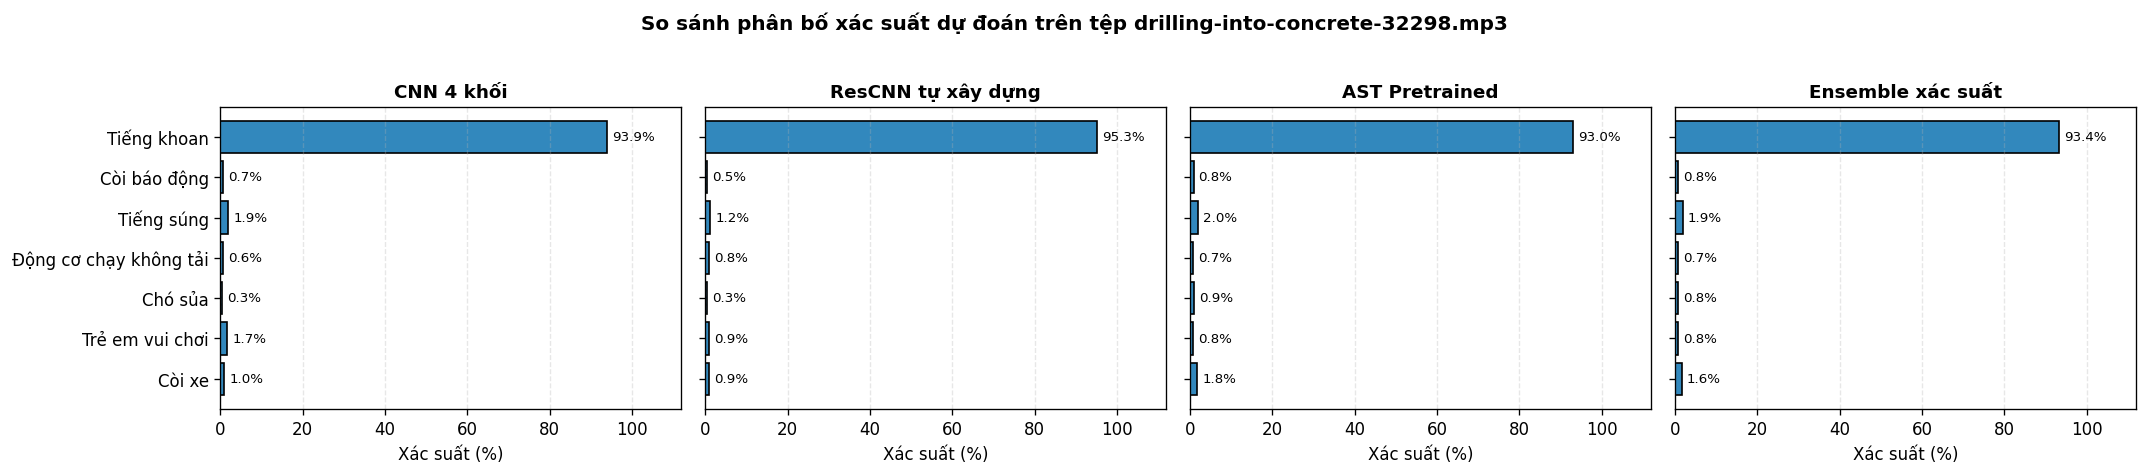

,Tệp âm thanh,Mô hình,Nhãn dự đoán,Độ tin cậy (%)
0,drilling-into-concrete-32298.mp3,CNN 4 khối,Tiếng khoan,93.91
1,drilling-into-concrete-32298.mp3,ResCNN tự xây dựng,Tiếng khoan,95.27
2,drilling-into-concrete-32298.mp3,AST Pretrained,Tiếng khoan,92.95
3,drilling-into-concrete-32298.mp3,Ensemble xác suất,Tiếng khoan,93.41


In [28]:
@torch.no_grad()
def predict_single_window(y_win):
    per_model_probs = {}
    for k, r in RUNS.items():
        model = r['model']
        model.eval()
        if k == 'ast':
            x = ast_fe(y_win, sampling_rate=CFG['sr'], return_tensors='pt')['input_values'].to(DEVICE)
        else:
            m = (extract_logmel_cnn(y_win, CFG) - CNN_MEAN[:, 0, :]) / CNN_STD[:, 0, :]
            x = torch.from_numpy(m)[None, None, ...].to(DEVICE)
        p = torch.softmax(model(x).float(), dim=-1).cpu().numpy()[0]
        per_model_probs[k] = p
    if len(model_keys) > 1:
        per_model_probs['ensemble'] = sum(w * per_model_probs[k] for w, k in zip(best_weights, model_keys))
    return per_model_probs

demo_path_obj = Path(CFG['demo_path'])
demo_files = []
if demo_path_obj.exists():
    if demo_path_obj.is_file():
        demo_files = [demo_path_obj]
    else:
        for ext in ('*.wav', '*.mp3', '*.flac', '*.ogg'):
            demo_files.extend(sorted(demo_path_obj.rglob(ext)))

if not demo_files:
    fallback_path = Path(test_df.iloc[0]['path'])
    print(f"Không tìm thấy file tại {CFG['demo_path']}, sử dụng file mẫu từ tập Test: {fallback_path.name}")
    demo_files = [fallback_path]
else:
    print(f"Tìm thấy {len(demo_files)} tệp âm thanh trong {CFG['demo_path']}.")

demo_summary_rows = []
for f_idx, f_path in enumerate(demo_files[:5]):
    y_full = load_audio(f_path, CFG['sr'], seconds=None)
    win_len = int(CFG['sr'] * CFG['seconds'])
    hop_len = int(CFG['sr'] * 2.0)
    starts = [0] if len(y_full) <= win_len else list(range(0, len(y_full) - win_len + 1, hop_len))

    agg_probs = {k: [] for k in EVAL_RESULTS.keys()}
    for st in starts:
        seg = y_full[st:st + win_len]
        if len(seg) < win_len:
            seg = np.pad(seg, (0, win_len - len(seg)))
        seg_probs = predict_single_window(seg)
        for k, p_vec in seg_probs.items():
            agg_probs[k].append(p_vec)

    mean_probs = {k: np.mean(v, axis=0) for k, v in agg_probs.items()}
    best_Demo_Key = 'ensemble' if 'ensemble' in mean_probs else best_single_key
    final_p = mean_probs[best_Demo_Key]
    pred_cls_id = int(final_p.argmax())

    display(Markdown(f"#### Tệp kiểm thử {f_idx+1}: `{f_path.name}` — Dự đoán: **{VI[pred_cls_id]}** ({final_p[pred_cls_id]*100:.2f}%)"))
    display(Audio(y_full, rate=CFG['sr']))

    for k, p_vec in mean_probs.items():
        top_i = int(p_vec.argmax())
        demo_summary_rows.append({
            'Tệp âm thanh': f_path.name,
            'Mô hình': EVAL_RESULTS[k]['name'],
            'Nhãn dự đoán': VI[top_i],
            'Độ tin cậy (%)': float(p_vec[top_i] * 100)
        })

    if f_idx == 0:
        fig_d, axes_d = plt.subplots(1, len(mean_probs), figsize=(4.5 * len(mean_probs), 3.8), sharey=True)
        if len(mean_probs) == 1:
            axes_d = [axes_d]
        for ax_i, (k, p_vec) in zip(axes_d, mean_probs.items()):
            bars = ax_i.barh(VI, p_vec * 100, color='#3288bd', edgecolor='black')
            ax_i.set_xlim(0, 112)
            ax_i.set_title(f"{EVAL_RESULTS[k]['name']}", fontweight='bold')
            ax_i.set_xlabel('Xác suất (%)')
            ax_i.grid(axis='x', linestyle='--', alpha=0.3)
            for b in bars:
                ax_i.annotate(f'{b.get_width():.1f}%', (b.get_width(), b.get_y() + b.get_height()/2),
                              xytext=(3, 0), textcoords='offset points', va='center', fontsize=8)
        fig_d.suptitle(f'So sánh phân bố xác suất dự đoán trên tệp {f_path.name}', fontweight='bold', y=1.03)
        fig_d.tight_layout()
        save_fig(fig_d, '15_demo_audio_prediction_comparison')
        plt.show()

demo_df = pd.DataFrame(demo_summary_rows)
demo_df.to_csv(PRED_DIR / 'demo_predictions.csv', index=False)
display(demo_df.round(2))


<a id="c10-2"></a>
## 10.2. Báo cáo kết quả


In [29]:
zip_base = Path('/kaggle/working') / f"{CFG['experiment_name']}_full_report"
shutil.make_archive(str(zip_base), 'zip', root_dir=ROOT)

print(f"Đã lưu toàn bộ biểu đồ chung, biểu đồ riêng từng mô hình (PNG 300 DPI & SVG) và số liệu CSV tại: {ROOT}")
print(f"Tệp ZIP tổng hợp để tải về máy: {zip_base}.zip")
display(FileLink(f"{zip_base}.zip"))

all_saved_pngs = sorted([str(p.relative_to(ROOT)) for p in FIGURES_DIR.rglob('*.png')])
print(f"\nDanh sách {len(all_saved_pngs)} file biểu đồ PNG đã lưu:")
for p_str in all_saved_pngs:
    print(" -", p_str)


Đã lưu toàn bộ biểu đồ chung, biểu đồ riêng từng mô hình (PNG 300 DPI & SVG) và số liệu CSV tại: /kaggle/working/urban_sound_7class
Tệp ZIP tổng hợp để tải về máy: /kaggle/working/urban_sound_7class_full_report.zip


/kaggle/working/urban_sound_7class_full_report.zip


Danh sách 29 file biểu đồ PNG đã lưu:
 - outputs/figures/01_eda_distribution.png
 - outputs/figures/02_eda_waveform_logmel.png
 - outputs/figures/03_split_distribution_by_class.png
 - outputs/figures/04_per_bin_zscore_normalization.png
 - outputs/figures/05_learning_curves_comparison.png
 - outputs/figures/06_individual_learning_curves.png
 - outputs/figures/07_train_validation_gap_and_stability.png
 - outputs/figures/08_test_accuracy_f1_comparison.png
 - outputs/figures/09_per_class_f1_comparison.png
 - outputs/figures/10_confusion_matrices_all_models.png
 - outputs/figures/11_top_confusion_errors.png
 - outputs/figures/12_roc_auc_all_models.png
 - outputs/figures/13_pca_embeddings_comparison.png
 - outputs/figures/14_fps_stability_accuracy_comprehensive.png
 - outputs/figures/15_demo_audio_prediction_comparison.png
 - outputs/figures/individual_models/confusion_matrix_ast.png
 - outputs/figures/individual_models/confusion_matrix_cnn4.png
 - outputs/figures/individual_models/confusio